# Modelo 3 — Árvore de Decisão para Predição de Falhas em PSDs

Este notebook tem como objetivo desenvolver um modelo de árvore de decisão capaz de estimar se uma posição individual do sistema de Portas de Plataforma (PSD) apresentará uma falha corretiva emergencial nos próximos 7 dias.

Cada PSD será identificada pela combinação de estação, via e posição da porta. Por exemplo, `FAL_V2_PSD09` representa a posição 09 da via 2 da estação FAL.

Para construir as variáveis de entrada, serão utilizados os alarmes dos componentes associados a cada PSD, principalmente:

- `PDM`: componente móvel da porta;
- `MDU`: unidade de controle associada à posição da porta.

As ordens corretivas emergenciais ZM01 que identificam uma porta específica serão utilizadas para construir o target de falha.

O desenvolvimento será dividido nas seguintes etapas:

1. Importação das bibliotecas;
2. Carregamento dos dados;
3. Análise e preparação das bases;
4. Identificação das PSDs e de seus componentes;
5. Preparação das ordens corretivas ZM01;
6. Construção das variáveis preditoras;
7. Construção do target de falha nos próximos 7 dias;
8. Separação temporal dos dados;
9. Treinamento da árvore de decisão;
10. Avaliação e interpretação dos resultados.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [27]:
# Localiza a raiz do projeto, independentemente de onde o Jupyter foi iniciado
diretorio_atual = Path.cwd().resolve()

if (diretorio_atual / "data").exists():
    raiz_projeto = diretorio_atual
elif (diretorio_atual.parent / "data").exists():
    raiz_projeto = diretorio_atual.parent
elif (diretorio_atual.parent.parent / "data").exists():
    raiz_projeto = diretorio_atual.parent.parent
else:
    raise FileNotFoundError("Não foi possível localizar a pasta data do projeto.")

caminho_alarmes = (
    raiz_projeto
    / "data"
    / "Alarmes"
    / "alarmes_trata_limpos_consolidado.csv"
)

caminho_zm01 = (
    raiz_projeto
    / "data"
    / "Corretiva Emergencial"
    / "processados"
    / "ZM01_limpa.xlsx"
)

print("Raiz do projeto:", raiz_projeto)
print("Base de alarmes encontrada:", caminho_alarmes.exists())
print("Base ZM01 encontrada:", caminho_zm01.exists())

Raiz do projeto: /home/cardoso/GitHub/g04
Base de alarmes encontrada: True
Base ZM01 encontrada: True


In [28]:
colunas_alarmes = [
    "TAG",
    "dt_alarme",
    "duracao_calculada_seg",
    "estacao_extraida",
    "plataforma_extraida",
    "porta_extraida",
    "Alarme"
]

alarmes = pd.read_csv(
    caminho_alarmes,
    usecols=colunas_alarmes,
    parse_dates=["dt_alarme"],
    low_memory=False
)

# Padroniza o nome da coluna para facilitar as próximas etapas
alarmes = alarmes.rename(
    columns={
        "Alarme": "tipo_alarme"
    }
)

print(f"Quantidade de registros: {len(alarmes):,}")
print(f"Quantidade de colunas: {alarmes.shape[1]}")

display(alarmes.head())

Quantidade de registros: 742,506
Quantidade de colunas: 7


,TAG,tipo_alarme,dt_alarme,duracao_calculada_seg,estacao_extraida,plataforma_extraida,porta_extraida
0,PSD_FAL_FAL2_PDM09_OBS,OBS,2026-05-12 08:16:52.657,1.013,FAL,FAL2,9.0
1,PSD_LUZ_LUZ1_PDM08_OBS,OBS,2026-05-12 08:15:09.913,1.004,LUZ,LUZ1,8.0
2,PSD_FAL_FAL1_PDM15_OBS,OBS,2026-05-12 08:14:06.657,1.013,FAL,FAL1,15.0
3,PSD_LUZ_LUZ1_PDM19_OBS,OBS,2026-05-12 08:09:31.930,0.987,LUZ,LUZ1,19.0
4,PSD_FRE_FRE1_PDM14_OBS,OBS,2026-05-12 08:05:05.830,9.017,FRE,FRE1,14.0


In [29]:
print("Dimensão da base:")
print(f"Linhas: {alarmes.shape[0]:,}")
print(f"Colunas: {alarmes.shape[1]}")

print("\nPeríodo dos alarmes:")
print("Data inicial:", alarmes["dt_alarme"].min())
print("Data final:", alarmes["dt_alarme"].max())

print("\nTipos das colunas:")
display(alarmes.dtypes.to_frame("tipo"))

print("\nValores ausentes:")
ausencias_alarmes = (
    alarmes.isna()
    .sum()
    .to_frame("quantidade_ausente")
)

ausencias_alarmes["percentual_ausente"] = (
    ausencias_alarmes["quantidade_ausente"]
    / len(alarmes)
    * 100
).round(2)

display(ausencias_alarmes)

Dimensão da base:
Linhas: 742,506
Colunas: 7

Período dos alarmes:
Data inicial: 2023-02-27 06:26:56.897000
Data final: 2026-05-12 08:16:52.657000

Tipos das colunas:


,tipo
TAG,str
tipo_alarme,str
dt_alarme,datetime64[us]
duracao_calculada_seg,float64
estacao_extraida,str
plataforma_extraida,str
porta_extraida,float64



Valores ausentes:


,quantidade_ausente,percentual_ausente
TAG,0,0.00
tipo_alarme,0,0.00
dt_alarme,0,0.00
duracao_calculada_seg,0,0.00
estacao_extraida,0,0.00
plataforma_extraida,0,0.00
porta_extraida,170,0.02


## 1. Identificação das PSDs e de seus componentes

Cada posição do sistema PSD será identificada pela combinação entre estação, via e número da porta. Os alarmes dos componentes `PDM` e `MDU` que possuem a mesma posição serão associados à mesma PSD.

Registros gerais do sistema que não identificam uma posição individual não serão utilizados neste modelo.

In [30]:
quantidade_inicial = len(alarmes)

# Padroniza a TAG antes da extração
tag_padronizada = (
    alarmes["TAG"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Identifica os componentes individualizáveis do sistema PSD
alarmes_psd = alarmes.copy()

alarmes_psd["componente"] = tag_padronizada.str.extract(
    r"(PDM|MDU)(?=\d)",
    expand=False
)

# Extrai a via de valores como FAL1, FAL2, BUT1 e BUT2
alarmes_psd["via"] = (
    alarmes_psd["plataforma_extraida"]
    .astype("string")
    .str.extract(r"(\d+)$", expand=False)
    .astype("Int64")
)

# Padroniza a estação
alarmes_psd["estacao"] = (
    alarmes_psd["estacao_extraida"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Converte o número da posição para inteiro
alarmes_psd["posicao_psd"] = (
    pd.to_numeric(
        alarmes_psd["porta_extraida"],
        errors="coerce"
    )
    .astype("Int64")
)

# Padroniza o tipo do alarme
alarmes_psd["tipo_alarme"] = (
    alarmes_psd["tipo_alarme"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Mantém apenas registros atribuíveis a uma PSD individual
alarmes_psd = alarmes_psd[
    alarmes_psd["componente"].isin(["PDM", "MDU"])
    & alarmes_psd["via"].isin([1, 2])
    & alarmes_psd["posicao_psd"].between(1, 24)
].copy()

# Cria o identificador único da PSD
alarmes_psd["id_psd"] = (
    alarmes_psd["estacao"]
    + "_V"
    + alarmes_psd["via"].astype("string")
    + "_PSD"
    + alarmes_psd["posicao_psd"]
        .astype("string")
        .str.zfill(2)
)

# Organiza os registros cronologicamente
alarmes_psd = (
    alarmes_psd
    .sort_values(["id_psd", "dt_alarme"])
    .reset_index(drop=True)
)

print(f"Registros originais: {quantidade_inicial:,}")
print(f"Registros atribuídos às PSDs: {len(alarmes_psd):,}")
print(
    "Registros gerais removidos:",
    f"{quantidade_inicial - len(alarmes_psd):,}"
)
print(f"Estações: {alarmes_psd['estacao'].nunique()}")
print(f"PSDs identificadas: {alarmes_psd['id_psd'].nunique()}")

print("\nRegistros por componente:")
display(
    alarmes_psd["componente"]
    .value_counts()
    .rename_axis("componente")
    .to_frame("quantidade")
)

display(
    alarmes_psd[
        [
            "TAG",
            "dt_alarme",
            "id_psd",
            "componente",
            "tipo_alarme",
            "duracao_calculada_seg"
        ]
    ].head()
)

Registros originais: 742,506
Registros atribuídos às PSDs: 742,336
Registros gerais removidos: 170
Estações: 11
PSDs identificadas: 526

Registros por componente:


,quantidade
componente,
PDM,678166
MDU,64170


,TAG,dt_alarme,id_psd,componente,tipo_alarme,duracao_calculada_seg
0,PSD_BUT_BUT1_PDM01_OBS,2024-01-21 23:12:46.257,BUT_V1_PSD01,PDM,OBS,2573380.513
1,PSD_P_BUT1_PDM01_CA,2024-01-21 23:12:46.257,BUT_V1_PSD01,PDM,CA,2573380.513
2,PSD_P_BUT1_PDM01_CSD,2024-01-21 23:12:46.257,BUT_V1_PSD01,PDM,CSD,2573380.513
3,PSD_P_BUT1_PDM01_FC,2024-01-21 23:12:46.257,BUT_V1_PSD01,PDM,FC,2573380.513
4,PSD_P_BUT1_PDM01_FO,2024-01-21 23:12:46.257,BUT_V1_PSD01,PDM,FO,2573380.513


## 2. Carregamento das ordens corretivas emergenciais ZM01

A base ZM01 contém as ordens de manutenção corretiva emergencial do sistema PSD. Ela será utilizada para identificar a ocorrência e o momento das falhas.

Nesta etapa, a base será apenas carregada e inspecionada. A associação entre cada ordem e uma PSD individual será realizada posteriormente por meio do local de instalação.

In [31]:
colunas_zm01 = [
    "linha_origem",
    "ordem",
    "descricao",
    "local_de_instalacao",
    "inicio_avaria_datetime",
    "falha_flag",
    "ordem_ausente_flag",
    "ordem_repetida_flag",
    "status_do_sistema_da_ordem",
    "sintoma",
    "objeto",
    "defeito",
    "causa"
]

zm01 = pd.read_excel(
    caminho_zm01,
    sheet_name="ZM01_limpa",
    usecols=colunas_zm01
)

# Garante que o início da avaria seja tratado como data e hora
zm01["inicio_avaria_datetime"] = pd.to_datetime(
    zm01["inicio_avaria_datetime"],
    errors="coerce"
)

print("Dimensão da ZM01:")
print(f"Linhas: {zm01.shape[0]:,}")
print(f"Colunas: {zm01.shape[1]}")

print("\nPeríodo das ordens:")
print(
    "Data inicial:",
    zm01["inicio_avaria_datetime"].min()
)
print(
    "Data final:",
    zm01["inicio_avaria_datetime"].max()
)

print("\nDistribuição da flag de falha:")
display(
    zm01["falha_flag"]
    .value_counts(dropna=False)
    .rename_axis("falha_flag")
    .to_frame("quantidade")
)

print("\nValores ausentes:")
ausencias_zm01 = (
    zm01.isna()
    .sum()
    .to_frame("quantidade_ausente")
)

ausencias_zm01["percentual_ausente"] = (
    ausencias_zm01["quantidade_ausente"]
    / len(zm01)
    * 100
).round(2)

display(ausencias_zm01)

display(zm01.head())

Dimensão da ZM01:
Linhas: 10,543
Colunas: 13

Período das ordens:
Data inicial: 2023-01-01 02:39:00
Data final: 2026-04-01 22:43:00

Distribuição da flag de falha:


,quantidade
falha_flag,
False,7150
True,3393



Valores ausentes:


,quantidade_ausente,percentual_ausente
linha_origem,0,0.00
ordem,1,0.01
descricao,0,0.00
local_de_instalacao,0,0.00
inicio_avaria_datetime,0,0.00
falha_flag,0,0.00
ordem_ausente_flag,0,0.00
ordem_repetida_flag,0,0.00
status_do_sistema_da_ordem,1,0.01
sintoma,0,0.00


,linha_origem,ordem,descricao,local_de_instalacao,inicio_avaria_datetime,falha_flag,ordem_ausente_flag,ordem_repetida_flag,status_do_sistema_da_ordem,sintoma,objeto,defeito,causa
0,2,53954586.0,PSD PL 01-02 Sem status para o CCO,SP04-6-PSD-BUT,2025-11-14 06:35:28,True,False,False,LIB CNPA CAPC ERRD MOME MATC NOLQ,LAÇO DE PDM ABERTO,NaN,NaN,NaN
1,3,54145839.0,PSD - PDM's não abriram PLT02,SP04-6-PSD-BUT,2026-02-27 07:33:00,False,False,False,ENTE CNPA CAPC NOLQ SCDM,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO
2,4,52913343.0,PSD server s/ status das plataformas,SP04-6-PSD-BUT-P1S1,2024-04-18 06:00:00,False,False,False,ENTE CNPA CAPC NOLQ SCDM,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE
3,5,53724958.0,BUT PLT 1 PORTAS NAO ABRIRAM,SP04-6-PSD-BUT-P1S1,2025-07-07 18:38:00,False,False,False,ENTE CNPA CAPC NOLQ SCDM,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE
4,6,53655728.0,PSD plt 1 - Falha geral de abertura,SP04-6-PSD-BUT-P1S1-PSSE1,2025-05-28 09:10:00,False,False,False,ENTE CNPA CAPC NOLQ SCDM,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC


## 3. Identificação das PSDs nas ordens ZM01

Para relacionar os alarmes às manutenções, será criado na ZM01 o mesmo identificador utilizado na base de alarmes.

Somente ordens cujo local de instalação informa estação, via e posição da porta podem ser atribuídas a uma PSD individual. Ordens gerais de estação, plataforma ou outros componentes serão preservadas na base original, mas não serão utilizadas como target individual.

A ocorrência de uma ordem ZM01 associada a uma PSD será utilizada como proxy de falha corretiva emergencial. A coluna `falha_flag` não será usada como filtro, pois sua ausência não significa necessariamente que não houve falha.

In [32]:
# Padroniza o local de instalação
local_padronizado = (
    zm01["local_de_instalacao"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Extrai estação, via e posição de locais como:
# SP04-6-PSD-BUT-PLT1-PP01PDM
identificacao_zm01 = local_padronizado.str.extract(
    (
        r"^SP04-6-PSD-"
        r"(?P<estacao>[A-Z]{3})-"
        r"PLT(?P<via>[12])-"
        r"PP(?P<posicao_psd>\d{2})PDM"
        r"(?:$|-)"
    )
)

# Junta a identificação extraída à base
zm01_identificada = pd.concat(
    [
        zm01.copy(),
        identificacao_zm01
    ],
    axis=1
)

# Mantém somente ordens atribuíveis a uma PSD individual
zm01_psd = zm01_identificada.dropna(
    subset=[
        "estacao",
        "via",
        "posicao_psd"
    ]
).copy()

# Converte via e posição para inteiros
zm01_psd["via"] = (
    pd.to_numeric(zm01_psd["via"], errors="coerce")
    .astype("Int64")
)

zm01_psd["posicao_psd"] = (
    pd.to_numeric(
        zm01_psd["posicao_psd"],
        errors="coerce"
    )
    .astype("Int64")
)

# Cria o mesmo identificador utilizado nos alarmes
zm01_psd["id_psd"] = (
    zm01_psd["estacao"]
    + "_V"
    + zm01_psd["via"].astype("string")
    + "_PSD"
    + zm01_psd["posicao_psd"]
        .astype("string")
        .str.zfill(2)
)

# Define o momento do evento corretivo
zm01_psd["dt_evento_corretivo"] = (
    zm01_psd["inicio_avaria_datetime"]
)

# Verifica se a PSD também existe na base de alarmes
ids_com_alarmes = set(
    alarmes_psd["id_psd"].unique()
)

zm01_psd["possui_historico_alarmes"] = (
    zm01_psd["id_psd"].isin(ids_com_alarmes)
)

# Organiza cronologicamente
zm01_psd = (
    zm01_psd
    .sort_values(["id_psd", "dt_evento_corretivo"])
    .reset_index(drop=True)
)

print(f"Ordens ZM01 totais: {len(zm01):,}")
print(
    "Ordens atribuídas a uma PSD individual:",
    f"{len(zm01_psd):,}"
)
print(
    "Ordens gerais ou de outros componentes:",
    f"{len(zm01) - len(zm01_psd):,}"
)
print(
    "PSDs diferentes presentes na ZM01:",
    zm01_psd["id_psd"].nunique()
)
print(
    "Ordens com PSD encontrada nos alarmes:",
    f"{zm01_psd['possui_historico_alarmes'].sum():,}"
)

print("\nDistribuição da flag de falha nas ordens individualizadas:")
display(
    zm01_psd["falha_flag"]
    .value_counts(dropna=False)
    .rename_axis("falha_flag")
    .to_frame("quantidade")
)

display(
    zm01_psd[
        [
            "ordem",
            "local_de_instalacao",
            "dt_evento_corretivo",
            "id_psd",
            "falha_flag",
            "possui_historico_alarmes"
        ]
    ].head()
)

Ordens ZM01 totais: 10,543
Ordens atribuídas a uma PSD individual: 9,260
Ordens gerais ou de outros componentes: 1,283
PSDs diferentes presentes na ZM01: 524
Ordens com PSD encontrada nos alarmes: 9,228

Distribuição da flag de falha nas ordens individualizadas:


,quantidade
falha_flag,
False,6220
True,3040


,ordem,local_de_instalacao,dt_evento_corretivo,id_psd,falha_flag,possui_historico_alarmes
0,52149458.0,SP04-6-PSD-BUT-PLT1-PP01PDM,2023-02-12 10:35:00,BUT_V1_PSD01,True,True
1,52485870.0,SP04-6-PSD-BUT-PLT1-PP01PDM,2023-08-25 16:53:00,BUT_V1_PSD01,False,True
2,52752879.0,SP04-6-PSD-BUT-PLT1-PP01PDM,2024-01-21 12:22:00,BUT_V1_PSD01,True,True
3,53017687.0,SP04-6-PSD-BUT-PLT1-PP01PDM,2024-06-17 05:45:00,BUT_V1_PSD01,True,True
4,53156524.0,SP04-6-PSD-BUT-PLT1-PP01PDM,2024-09-01 16:16:00,BUT_V1_PSD01,True,True


## 4. Definição do período observável para modelagem

As bases de alarmes e de manutenções possuem períodos de cobertura diferentes entre estações e vias. Por isso, não é correto considerar automaticamente como “sem falha” um período no qual os dados não estavam disponíveis.

Para cada estação e via, será definido:

- O início da cobertura dos alarmes;
- O fim da cobertura dos alarmes;
- Uma janela histórica mínima de 30 dias para calcular as variáveis preditoras;
- Um horizonte futuro completo de 7 dias para observar o target.

A cobertura será calculada por estação e via, e não pela data do último alarme de cada porta. Uma PSD sem alarmes recentes pode estar funcionando normalmente, enquanto outras portas da mesma via confirmam que o sistema continuava sendo monitorado.

In [33]:
HORIZONTE_PREVISAO_DIAS = 7
JANELA_HISTORICO_DIAS = 30

# Calcula o período de cobertura dos alarmes por estação e via
cobertura_via = (
    alarmes_psd
    .groupby(
        ["estacao", "via"],
        as_index=False
    )
    .agg(
        inicio_cobertura_alarmes=(
            "dt_alarme",
            "min"
        ),
        fim_cobertura_alarmes=(
            "dt_alarme",
            "max"
        ),
        quantidade_alarmes=(
            "dt_alarme",
            "size"
        ),
        quantidade_psds=(
            "id_psd",
            "nunique"
        )
    )
)

# Identifica todas as PSDs observadas nos alarmes
psds_observadas = (
    alarmes_psd[
        [
            "id_psd",
            "estacao",
            "via",
            "posicao_psd"
        ]
    ]
    .drop_duplicates()
)

# Associa cada PSD à cobertura de sua estação e via
cobertura_psd = psds_observadas.merge(
    cobertura_via,
    on=["estacao", "via"],
    how="left",
    validate="many_to_one"
)

# Última data conhecida na base de corretivas
ultima_data_zm01 = (
    zm01_psd["dt_evento_corretivo"]
    .max()
    .normalize()
)

# A data de referência precisa possuir sete dias futuros completos
ultima_data_referencia = (
    ultima_data_zm01
    - pd.Timedelta(
        days=HORIZONTE_PREVISAO_DIAS
    )
)

# Reserva 30 dias iniciais para a criação das features históricas
cobertura_psd["inicio_modelagem"] = (
    cobertura_psd["inicio_cobertura_alarmes"]
    .dt.normalize()
    + pd.Timedelta(
        days=JANELA_HISTORICO_DIAS
    )
)

# O fim da modelagem não pode ultrapassar:
# 1. o fim dos alarmes daquela via;
# 2. a última data com target futuro completo.
cobertura_psd["fim_modelagem"] = (
    cobertura_psd["fim_cobertura_alarmes"]
    .dt.normalize()
    .clip(upper=ultima_data_referencia)
)

# Mantém apenas intervalos válidos
cobertura_psd = cobertura_psd[
    cobertura_psd["inicio_modelagem"]
    <= cobertura_psd["fim_modelagem"]
].copy()

# Calcula quantos dias poderão ser usados para cada PSD
cobertura_psd["quantidade_dias_modelagem"] = (
    cobertura_psd["fim_modelagem"]
    - cobertura_psd["inicio_modelagem"]
).dt.days + 1

# Mantém somente eventos de PSDs que também existem nos alarmes
ids_psd_observadas = set(
    cobertura_psd["id_psd"].unique()
)

eventos_corretivos_compativeis = zm01_psd[
    zm01_psd["id_psd"].isin(
        ids_psd_observadas
    )
].copy()

quantidade_linhas_estimadas = (
    cobertura_psd["quantidade_dias_modelagem"]
    .sum()
)

print(
    "Horizonte de previsão:",
    HORIZONTE_PREVISAO_DIAS,
    "dias"
)
print(
    "Janela histórica:",
    JANELA_HISTORICO_DIAS,
    "dias"
)
print(
    "Última data disponível na ZM01:",
    ultima_data_zm01.date()
)
print(
    "Última data possível de referência:",
    ultima_data_referencia.date()
)
print(
    "Estações e vias monitoradas:",
    len(cobertura_via)
)
print(
    "PSDs com período válido:",
    len(cobertura_psd)
)
print(
    "Eventos corretivos com PSD compatível:",
    f"{len(eventos_corretivos_compativeis):,}"
)
print(
    "Quantidade estimada de linhas diárias:",
    f"{quantidade_linhas_estimadas:,}"
)

display(
    cobertura_via[
        [
            "estacao",
            "via",
            "inicio_cobertura_alarmes",
            "fim_cobertura_alarmes",
            "quantidade_alarmes",
            "quantidade_psds"
        ]
    ]
)

Horizonte de previsão: 7 dias
Janela histórica: 30 dias
Última data disponível na ZM01: 2026-04-01
Última data possível de referência: 2026-03-25
Estações e vias monitoradas: 22
PSDs com período válido: 526
Eventos corretivos com PSD compatível: 9,228
Quantidade estimada de linhas diárias: 404,206


,estacao,via,inicio_cobertura_alarmes,fim_cobertura_alarmes,quantidade_alarmes,quantidade_psds
0,BUT,1,2023-10-17 21:44:30.900,2026-05-12 05:52:14.727,54407,24
1,BUT,2,2023-10-18 13:31:20.830,2026-05-11 08:25:56.703,37398,24
2,FAL,1,2023-10-17 22:53:09.517,2026-05-12 08:14:06.657,12183,24
3,FAL,2,2023-10-18 04:37:39.913,2026-05-12 08:16:52.657,15040,24
4,FRA,1,2023-10-18 21:14:59.083,2026-04-14 18:15:03.857,67416,24
5,FRA,2,2023-10-18 17:15:18.943,2026-04-14 19:28:40.883,91825,24
6,FRE,1,2023-02-27 06:26:56.897,2026-05-12 08:05:05.830,560,22
7,FRE,2,2023-02-27 16:58:24.710,2026-05-11 18:23:52.690,1601,24
8,HIG,1,2023-10-18 22:23:13.977,2026-05-12 07:52:23.820,37852,24
9,HIG,2,2023-10-17 22:22:55.643,2026-05-12 05:48:17.740,54088,24


## 5. Construção da grade diária e do resumo de alarmes

Será criada primeiro uma grade diária intermediária para calcular corretamente os históricos, inclusive nos dias em que uma PSD não gerou alarmes. Depois do cálculo das features, o modelo manterá apenas uma data de referência por semana.

Os alarmes serão resumidos diariamente por PSD, componente, tipo e duração. Registros com menos de 30 segundos serão removidos antes das agregações. Para impedir vazamento temporal, o filtro usa somente a duração observável até o final do próprio dia de início: alarmes ainda ativos não utilizam antecipadamente sua duração final. A grade começa no início da cobertura dos alarmes para que os 30 dias anteriores à primeira data de modelagem estejam disponíveis para o cálculo das features.

In [34]:
# Define o dia de ocorrência de cada alarme
alarmes_psd["data_alarme"] = (
    alarmes_psd["dt_alarme"].dt.normalize()
)

# Limita a duração à informação disponível no fim do dia do alarme
segundos_ate_fim_dia = (
    alarmes_psd["data_alarme"]
    + pd.Timedelta(days=1)
    - alarmes_psd["dt_alarme"]
).dt.total_seconds().clip(lower=0)

alarmes_psd["duracao_observada_dia_seg"] = np.minimum(
    alarmes_psd["duracao_calculada_seg"],
    segundos_ate_fim_dia
)

assert (
    alarmes_psd["duracao_observada_dia_seg"]
    <= segundos_ate_fim_dia
).all()
assert (
    alarmes_psd["duracao_observada_dia_seg"] >= 0
).all()

# Remove alarmes com duração observável menor que 30 segundos
DURACAO_MINIMA_ALARME_SEG = 30
quantidade_antes_filtro_duracao = len(alarmes_psd)

alarmes_psd = alarmes_psd[
    alarmes_psd["duracao_observada_dia_seg"]
    >= DURACAO_MINIMA_ALARME_SEG
].copy()

quantidade_alarmes_curtos_removidos = (
    quantidade_antes_filtro_duracao - len(alarmes_psd)
)

assert (
    alarmes_psd["duracao_observada_dia_seg"]
    >= DURACAO_MINIMA_ALARME_SEG
).all()

print(
    "Alarmes com menos de 30 segundos removidos:",
    f"{quantidade_alarmes_curtos_removidos:,}"
)
print("Alarmes mantidos:", f"{len(alarmes_psd):,}")

# Indicadores usados nas agregações diárias
alarmes_psd["indicador_pdm"] = (
    alarmes_psd["componente"] == "PDM"
).astype("int8")

alarmes_psd["indicador_mdu"] = (
    alarmes_psd["componente"] == "MDU"
).astype("int8")

alarmes_psd["indicador_critico"] = (
    alarmes_psd["duracao_observada_dia_seg"] > 30
).astype("int8")

# Resumo geral por PSD e dia
alarmes_diarios = (
    alarmes_psd
    .groupby(
        ["id_psd", "data_alarme"],
        as_index=False
    )
    .agg(
        qtd_alarmes_dia=("TAG", "size"),
        qtd_pdm_dia=("indicador_pdm", "sum"),
        qtd_mdu_dia=("indicador_mdu", "sum"),
        qtd_criticos_dia=("indicador_critico", "sum"),
        duracao_total_dia=("duracao_observada_dia_seg", "sum"),
        duracao_max_dia=("duracao_observada_dia_seg", "max"),
        ultimo_alarme_dia=("dt_alarme", "max")
    )
)

# Quantidade diária de cada tipo de alarme
contagem_tipos_dia = pd.crosstab(
    index=[
        alarmes_psd["id_psd"],
        alarmes_psd["data_alarme"]
    ],
    columns=alarmes_psd["tipo_alarme"]
).reset_index()

contagem_tipos_dia.columns = (
    ["id_psd", "data_alarme"]
    + [
        f"qtd_{str(tipo).lower()}_dia"
        for tipo in contagem_tipos_dia.columns[2:]
    ]
)

alarmes_diarios = alarmes_diarios.merge(
    contagem_tipos_dia,
    on=["id_psd", "data_alarme"],
    how="left",
    validate="one_to_one"
)

# Cria a grade completa, incluindo dias sem alarmes
cobertura_historica = cobertura_psd[
    [
        "id_psd",
        "estacao",
        "via",
        "posicao_psd",
        "inicio_cobertura_alarmes",
        "inicio_modelagem",
        "fim_modelagem"
    ]
].copy()

cobertura_historica["inicio_grade"] = (
    cobertura_historica["inicio_cobertura_alarmes"]
    .dt.normalize()
)

cobertura_historica["data_referencia"] = (
    cobertura_historica.apply(
        lambda linha: pd.date_range(
            linha["inicio_grade"],
            linha["fim_modelagem"],
            freq="D"
        ),
        axis=1
    )
)

grade_historica = (
    cobertura_historica
    .explode("data_referencia", ignore_index=True)
    .drop(columns="inicio_grade")
)

grade_historica["data_referencia"] = pd.to_datetime(
    grade_historica["data_referencia"]
)

grade_historica = (
    grade_historica
    .merge(
        alarmes_diarios,
        left_on=["id_psd", "data_referencia"],
        right_on=["id_psd", "data_alarme"],
        how="left",
        validate="one_to_one"
    )
    .drop(columns="data_alarme")
)

colunas_contagem_dia = [
    coluna
    for coluna in alarmes_diarios.columns
    if coluna.startswith("qtd_")
]

grade_historica[colunas_contagem_dia] = (
    grade_historica[colunas_contagem_dia].fillna(0)
)

grade_historica[
    ["duracao_total_dia", "duracao_max_dia"]
] = grade_historica[
    ["duracao_total_dia", "duracao_max_dia"]
].fillna(0)

grade_historica["teve_alarme_dia"] = (
    grade_historica["qtd_alarmes_dia"] > 0
).astype("int8")

grade_historica = (
    grade_historica
    .sort_values(["id_psd", "data_referencia"])
    .reset_index(drop=True)
)

print(
    "Dias com pelo menos um alarme:",
    f"{len(alarmes_diarios):,}"
)
print(
    "Linhas da grade com período histórico:",
    f"{len(grade_historica):,}"
)

display(alarmes_diarios.head())

Alarmes com menos de 30 segundos removidos: 244,910
Alarmes mantidos: 497,426
Dias com pelo menos um alarme: 23,365
Linhas da grade com período histórico: 419,986


,id_psd,data_alarme,qtd_alarmes_dia,qtd_pdm_dia,qtd_mdu_dia,qtd_criticos_dia,duracao_total_dia,duracao_max_dia,ultimo_alarme_dia,qtd_ca_dia,qtd_csd_dia,qtd_fc_dia,qtd_fo_dia,qtd_lsd_dia,qtd_oa_dia,qtd_obs_dia,qtd_rce_dia,qtd_sts_dia
0,BUT_V1_PSD01,2024-01-21,224,224,0,224,6.347584e+05,2833.743,2024-01-21 23:12:46.257,32,32,32,32,32,32,32,0,0
1,BUT_V1_PSD01,2024-04-13,155,155,0,155,1.249911e+07,81162.790,2024-04-13 01:27:17.210,22,22,22,22,22,23,22,0,0
2,BUT_V1_PSD01,2024-05-23,110,84,26,110,2.231320e+06,20656.013,2024-05-23 18:15:43.987,12,12,12,12,12,12,12,0,26
3,BUT_V1_PSD01,2024-06-03,9,9,0,9,1.352505e+05,19306.507,2024-06-03 18:38:13.493,1,1,1,1,1,3,1,0,0
4,BUT_V1_PSD01,2024-06-04,2,2,0,2,1.050040e+02,65.000,2024-06-04 21:00:56.147,0,0,0,0,0,2,0,0,0


## 6. Construção das features históricas

As variáveis preditoras serão calculadas utilizando somente os alarmes ocorridos até o fim da data de referência. Serão consideradas janelas de 1, 7 e 30 dias para representar o comportamento imediato, semanal e mensal de cada PSD.

As features incluem contagens gerais, contagens por componente e tipo de alarme, duração acumulada, duração máxima, duração média, quantidade de dias com alarmes e tempo desde o último alarme.

In [35]:
JANELAS_FEATURES_DIAS = [1, 7, 30]

colunas_soma_diaria = (
    colunas_contagem_dia
    + ["duracao_total_dia", "teve_alarme_dia"]
)

nomes_features = {
    "qtd_alarmes_dia": "qtd_alarmes",
    "qtd_pdm_dia": "qtd_pdm",
    "qtd_mdu_dia": "qtd_mdu",
    "qtd_criticos_dia": "qtd_criticos",
    "duracao_total_dia": "duracao_total",
    "teve_alarme_dia": "qtd_dias_com_alarme"
}

for coluna in colunas_contagem_dia:
    if coluna not in nomes_features:
        nomes_features[coluna] = coluna.removesuffix("_dia")

features_calculadas = {}
colunas_features_numericas = []

for janela in JANELAS_FEATURES_DIAS:
    somas_rolantes = (
        grade_historica
        .groupby("id_psd", sort=False)[colunas_soma_diaria]
        .rolling(window=janela, min_periods=1)
        .sum()
        .reset_index(level=0, drop=True)
        .reindex(grade_historica.index)
    )

    for coluna in colunas_soma_diaria:
        nome_feature = (
            f"{nomes_features[coluna]}_{janela}d"
        )
        features_calculadas[nome_feature] = (
            somas_rolantes[coluna].to_numpy()
        )
        colunas_features_numericas.append(nome_feature)

    maximos_rolantes = (
        grade_historica
        .groupby("id_psd", sort=False)["duracao_max_dia"]
        .rolling(window=janela, min_periods=1)
        .max()
        .reset_index(level=0, drop=True)
        .reindex(grade_historica.index)
    )

    nome_maximo = f"duracao_max_{janela}d"
    features_calculadas[nome_maximo] = (
        maximos_rolantes.to_numpy()
    )
    colunas_features_numericas.append(nome_maximo)

    quantidade = somas_rolantes["qtd_alarmes_dia"].to_numpy()
    duracao_total = (
        somas_rolantes["duracao_total_dia"].to_numpy()
    )
    nome_media = f"duracao_media_{janela}d"

    features_calculadas[nome_media] = np.divide(
        duracao_total,
        quantidade,
        out=np.zeros_like(duracao_total, dtype="float64"),
        where=quantidade > 0
    )
    colunas_features_numericas.append(nome_media)

features_rolantes = pd.DataFrame(
    features_calculadas,
    index=grade_historica.index
)

# Calcula a recência do último alarme sem olhar datas futuras
ultimo_alarme_conhecido = (
    grade_historica
    .groupby("id_psd", sort=False)["ultimo_alarme_dia"]
    .ffill()
)

features_rolantes["horas_desde_ultimo_alarme"] = (
    (
        grade_historica["data_referencia"]
        + pd.Timedelta(days=1)
        - ultimo_alarme_conhecido
    )
    .dt.total_seconds()
    .div(3600)
    .clip(
        lower=0,
        upper=JANELA_HISTORICO_DIAS * 24
    )
    .fillna(JANELA_HISTORICO_DIAS * 24)
)

features_rolantes["sem_alarme_30d"] = (
    features_rolantes["qtd_alarmes_30d"] == 0
).astype("int8")

colunas_features_numericas.extend(
    [
        "horas_desde_ultimo_alarme",
        "sem_alarme_30d"
    ]
)

grade_historica = pd.concat(
    [grade_historica, features_rolantes],
    axis=1
)

print(
    "Features numéricas criadas:",
    len(colunas_features_numericas)
)
print(
    "Valores ausentes nas features:",
    int(
        grade_historica[
            colunas_features_numericas
        ].isna().sum().sum()
    )
)

Features numéricas criadas: 53
Valores ausentes nas features: 0


## 7. Construção do target de falha nos próximos 7 dias

O target será igual a `1` quando a mesma PSD possuir uma ordem corretiva emergencial ZM01 entre o dia seguinte à data de referência e os sete dias posteriores. Caso contrário, será igual a `0`.

A ocorrência no próprio dia da referência não será incluída no target. Dessa forma, alarmes registrados no dia da falha não serão usados para afirmar que o modelo antecipou um evento que já estava acontecendo.

Também serão criadas features de reincidência corretiva e de tempo desde a última corretiva, ambas limitadas à janela histórica de 30 dias. Todas usam somente eventos estritamente anteriores à data de referência.

In [36]:
# Remove da grade os 30 dias reservados exclusivamente ao histórico
base_modelagem = grade_historica[
    grade_historica["data_referencia"]
    >= grade_historica["inicio_modelagem"]
].copy()

# Converte as corretivas para eventos diários e evita duplicidade
eventos_corretivos_diarios = (
    eventos_corretivos_compativeis[
        ["id_psd", "dt_evento_corretivo"]
    ]
    .assign(
        data_evento=lambda dados: (
            dados["dt_evento_corretivo"].dt.normalize()
        )
    )
    [["id_psd", "data_evento"]]
    .drop_duplicates()
)

# Histórico corretivo conhecido antes de cada data de referência
colunas_features_corretivas = [
    "qtd_corretivas_30d",
    "dias_desde_ultima_corretiva_30d",
    "sem_corretiva_30d"
]

base_modelagem = (
    base_modelagem
    .sort_values(["id_psd", "data_referencia"])
    .reset_index(drop=True)
)

for coluna in colunas_features_corretivas:
    base_modelagem[coluna] = 0

for id_psd, indices in base_modelagem.groupby(
    "id_psd",
    sort=False
).groups.items():
    indices = np.asarray(list(indices))
    datas_referencia = (
        base_modelagem.loc[indices, "data_referencia"]
        .to_numpy(dtype="datetime64[D]")
        .astype("int64")
    )
    datas_eventos = (
        eventos_corretivos_diarios.loc[
            eventos_corretivos_diarios["id_psd"] == id_psd,
            "data_evento"
        ]
        .to_numpy(dtype="datetime64[D]")
        .astype("int64")
    )
    datas_eventos = np.sort(np.unique(datas_eventos))

    # side='left' exclui corretivas ocorridas na própria referência
    posicao_evento_anterior = np.searchsorted(
        datas_eventos,
        datas_referencia,
        side="left"
    )

    for janela in [30]:
        inicio_janela = np.searchsorted(
            datas_eventos,
            datas_referencia - janela,
            side="left"
        )
        base_modelagem.loc[
            indices,
            f"qtd_corretivas_{janela}d"
        ] = (posicao_evento_anterior - inicio_janela)

    indice_ultimo_evento = posicao_evento_anterior - 1
    possui_evento_anterior = indice_ultimo_evento >= 0
    dias_desde_evento = np.full(
        len(datas_referencia),
        30,
        dtype="int16"
    )
    dias_desde_evento[possui_evento_anterior] = np.minimum(
        datas_referencia[possui_evento_anterior]
        - datas_eventos[
            indice_ultimo_evento[possui_evento_anterior]
        ],
        30
    )

    base_modelagem.loc[
        indices,
        "dias_desde_ultima_corretiva_30d"
    ] = dias_desde_evento
    base_modelagem.loc[
        indices,
        "sem_corretiva_30d"
    ] = (
        base_modelagem.loc[
            indices,
            "qtd_corretivas_30d"
        ] == 0
    ).astype("int8")

# Cada evento torna positivos os sete dias que o antecedem
referencias_positivas = pd.concat(
    [
        eventos_corretivos_diarios.assign(
            data_referencia=(
                eventos_corretivos_diarios["data_evento"]
                - pd.Timedelta(days=deslocamento)
            )
        )
        for deslocamento in range(
            1,
            HORIZONTE_PREVISAO_DIAS + 1
        )
    ],
    ignore_index=True
)[
    ["id_psd", "data_referencia"]
].drop_duplicates()

referencias_positivas["target_falha_7d"] = 1

base_modelagem = base_modelagem.merge(
    referencias_positivas,
    on=["id_psd", "data_referencia"],
    how="left",
    validate="one_to_one"
)

base_modelagem["target_falha_7d"] = (
    base_modelagem["target_falha_7d"]
    .fillna(0)
    .astype("int8")
)

# Variáveis de calendário conhecidas na data da previsão
base_modelagem["dia_semana"] = (
    base_modelagem["data_referencia"]
    .dt.dayofweek
    .astype("int8")
)

base_modelagem["fim_de_semana"] = (
    base_modelagem["dia_semana"]
    .isin([5, 6])
    .astype("int8")
)

base_modelagem["mes"] = (
    base_modelagem["data_referencia"]
    .dt.month
    .astype("int8")
)

# Faz uma previsão por PSD a cada semana. No domingo, o modelo
# estima se haverá falha em algum dos sete dias seguintes.
base_modelagem = base_modelagem[
    base_modelagem["data_referencia"].dt.dayofweek == 6
].copy()

distribuicao_target = (
    base_modelagem["target_falha_7d"]
    .value_counts()
    .sort_index()
    .rename_axis("target_falha_7d")
    .to_frame("quantidade")
)

distribuicao_target["percentual"] = (
    distribuicao_target["quantidade"]
    / len(base_modelagem)
    * 100
).round(2)

print(
    "Linhas da base de modelagem:",
    f"{len(base_modelagem):,}"
)
print(
    "Eventos corretivos em dias distintos:",
    f"{len(eventos_corretivos_diarios):,}"
)
print("Frequência das previsões: uma vez por semana")
display(distribuicao_target)

Linhas da base de modelagem: 57,792
Eventos corretivos em dias distintos: 7,907
Frequência das previsões: uma vez por semana


,quantidade,percentual
target_falha_7d,,
0,53149,91.97
1,4643,8.03


## 8. Consolidação e validação da base pré-processada

A tabela final manterá os identificadores necessários para auditoria, as features históricas selecionadas e o target. Cada linha representa uma PSD em um domingo e responde se haverá falha nos sete dias seguintes.

A seleção remove estação, via, posição, calendário e durações. Esses grupos aumentavam a dependência do contexto e não melhoravam o equilíbrio entre precisão e recall na validação. Permanecem contagens de alarmes, recência e histórico corretivo anterior. Não será aplicada padronização de escala, pois árvores de decisão não dependem da escala numérica das features.

In [37]:
colunas_metadados = [
    "estacao",
    "via",
    "posicao_psd"
]

colunas_duracao_removidas = [
    coluna
    for coluna in colunas_features_numericas
    if coluna.startswith("duracao_")
]

colunas_features_alarmes_selecionadas = [
    coluna
    for coluna in colunas_features_numericas
    if coluna not in colunas_duracao_removidas
]

colunas_features_modelo = (
    colunas_features_alarmes_selecionadas
    + colunas_features_corretivas
)

dados_modelagem = base_modelagem[
    ["id_psd", "data_referencia"]
    + colunas_metadados
    + colunas_features_modelo
    + ["target_falha_7d"]
].copy()

# Reduz o consumo de memória sem alterar o significado das features
dados_modelagem["via"] = (
    dados_modelagem["via"].astype("int8")
)
dados_modelagem["posicao_psd"] = (
    dados_modelagem["posicao_psd"].astype("int8")
)

for coluna in colunas_features_modelo:
    if (
        coluna.startswith("qtd_")
        or coluna.startswith("sem_")
        or coluna == "dias_desde_ultima_corretiva_30d"
    ):
        dados_modelagem[coluna] = pd.to_numeric(
            dados_modelagem[coluna],
            downcast="integer"
        )
    else:
        dados_modelagem[coluna] = pd.to_numeric(
            dados_modelagem[coluna],
            downcast="float"
        )

# Validações que devem ser satisfeitas antes do treinamento
quantidade_duplicadas = dados_modelagem.duplicated(
    ["id_psd", "data_referencia"]
).sum()

quantidade_ausentes = dados_modelagem[
    colunas_features_modelo
].isna().sum().sum()

matriz_numerica = dados_modelagem[
    colunas_features_modelo
].to_numpy(dtype="float64")

quantidade_nao_finitos = (
    ~np.isfinite(matriz_numerica)
).sum()

assert quantidade_duplicadas == 0
assert quantidade_ausentes == 0
assert quantidade_nao_finitos == 0
assert dados_modelagem["target_falha_7d"].nunique() == 2

X_base = dados_modelagem[colunas_features_modelo].copy()
y = dados_modelagem["target_falha_7d"].copy()

memoria_mb = (
    dados_modelagem.memory_usage(deep=True).sum()
    / 1024 ** 2
)

print(f"Linhas finais: {len(dados_modelagem):,}")
print(f"PSDs finais: {dados_modelagem['id_psd'].nunique()}")
print(
    "Período final:",
    dados_modelagem["data_referencia"].min().date(),
    "até",
    dados_modelagem["data_referencia"].max().date()
)
print(f"Features do modelo: {len(colunas_features_modelo)}")
print(f"Features de duração removidas: {len(colunas_duracao_removidas)}")
print("Features de contexto e calendário removidas: 6")
print(f"Linhas duplicadas: {quantidade_duplicadas}")
print(f"Valores ausentes: {quantidade_ausentes}")
print(f"Valores não finitos: {quantidade_nao_finitos}")
print(f"Memória aproximada: {memoria_mb:.1f} MB")

display(dados_modelagem.head())

Linhas finais: 57,792
PSDs finais: 526
Período final: 2023-04-02 até 2026-03-22
Features do modelo: 47
Features de duração removidas: 9
Features de contexto e calendário removidas: 6
Linhas duplicadas: 0
Valores ausentes: 0
Valores não finitos: 0
Memória aproximada: 11.9 MB


,id_psd,data_referencia,estacao,via,posicao_psd,qtd_alarmes_1d,qtd_pdm_1d,qtd_mdu_1d,qtd_criticos_1d,qtd_ca_1d,qtd_csd_1d,qtd_fc_1d,qtd_fo_1d,qtd_lsd_1d,qtd_oa_1d,qtd_obs_1d,qtd_rce_1d,qtd_sts_1d,qtd_dias_com_alarme_1d,qtd_alarmes_7d,qtd_pdm_7d,qtd_mdu_7d,qtd_criticos_7d,qtd_ca_7d,qtd_csd_7d,qtd_fc_7d,qtd_fo_7d,qtd_lsd_7d,qtd_oa_7d,qtd_obs_7d,qtd_rce_7d,qtd_sts_7d,qtd_dias_com_alarme_7d,qtd_alarmes_30d,qtd_pdm_30d,qtd_mdu_30d,qtd_criticos_30d,qtd_ca_30d,qtd_csd_30d,qtd_fc_30d,qtd_fo_30d,qtd_lsd_30d,qtd_oa_30d,qtd_obs_30d,qtd_rce_30d,qtd_sts_30d,qtd_dias_com_alarme_30d,horas_desde_ultimo_alarme,sem_alarme_30d,qtd_corretivas_30d,dias_desde_ultima_corretiva_30d,sem_corretiva_30d,target_falha_7d
3,BUT_V1_PSD01,2023-11-19,BUT,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,720.0,1,0,30,1,0
10,BUT_V1_PSD01,2023-11-26,BUT,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,720.0,1,0,30,1,0
17,BUT_V1_PSD01,2023-12-03,BUT,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,720.0,1,0,30,1,0
24,BUT_V1_PSD01,2023-12-10,BUT,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,720.0,1,0,30,1,0
31,BUT_V1_PSD01,2023-12-17,BUT,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,720.0,1,0,30,1,0


## 9. Divisão temporal em treino, validação e teste

A base é separada cronologicamente, sem embaralhamento, para simular o uso real do modelo: ele aprende com o passado e é avaliado em períodos posteriores.

Como o target considera falhas nos 7 dias seguintes, são retirados 7 dias entre treino e validação e entre validação e teste. Essa purga impede a sobreposição das janelas futuras usadas para construir o target e reduz o risco de vazamento temporal.

- **Treino:** 02/04/2023 a 23/03/2025;
- **Validação:** 06/04/2025 a 21/09/2025;
- **Teste:** 05/10/2025 a 22/03/2026.

In [38]:
DATA_INICIO_VALIDACAO = pd.Timestamp("2025-04-01")
DATA_INICIO_TESTE = pd.Timestamp("2025-10-01")
DIAS_PURGA = HORIZONTE_PREVISAO_DIAS

# O último target de cada conjunto deve terminar antes do próximo período
DATA_FIM_TREINO = (
    DATA_INICIO_VALIDACAO
    - pd.Timedelta(days=DIAS_PURGA + 1)
)
DATA_FIM_VALIDACAO = (
    DATA_INICIO_TESTE
    - pd.Timedelta(days=DIAS_PURGA + 1)
)

mascara_treino = (
    dados_modelagem["data_referencia"] <= DATA_FIM_TREINO
)
mascara_validacao = (
    dados_modelagem["data_referencia"] >= DATA_INICIO_VALIDACAO
) & (
    dados_modelagem["data_referencia"] <= DATA_FIM_VALIDACAO
)
mascara_teste = (
    dados_modelagem["data_referencia"] >= DATA_INICIO_TESTE
)

dados_treino = dados_modelagem.loc[mascara_treino].copy()
dados_validacao = dados_modelagem.loc[mascara_validacao].copy()
dados_teste = dados_modelagem.loc[mascara_teste].copy()

mascara_utilizada = (
    mascara_treino | mascara_validacao | mascara_teste
)
dados_purga = dados_modelagem.loc[~mascara_utilizada].copy()

X_treino = dados_treino[colunas_features_modelo].copy()
y_treino = dados_treino["target_falha_7d"].copy()

X_validacao = dados_validacao[colunas_features_modelo].copy()
y_validacao = dados_validacao["target_falha_7d"].copy()

X_teste = dados_teste[colunas_features_modelo].copy()
y_teste = dados_teste["target_falha_7d"].copy()

def resumir_conjunto(nome, dados):
    return {
        "conjunto": nome,
        "data_inicial": dados["data_referencia"].min().date(),
        "data_final": dados["data_referencia"].max().date(),
        "linhas": len(dados),
        "psds": dados["id_psd"].nunique(),
        "falhas_positivas": int(dados["target_falha_7d"].sum()),
        "taxa_falha_pct": (
            dados["target_falha_7d"].mean() * 100
        )
    }

resumo_divisao_temporal = pd.DataFrame([
    resumir_conjunto("Treino", dados_treino),
    resumir_conjunto("Validação", dados_validacao),
    resumir_conjunto("Teste", dados_teste)
])
resumo_divisao_temporal["taxa_falha_pct"] = (
    resumo_divisao_temporal["taxa_falha_pct"].round(2)
)

# Validações da separação temporal
assert len(dados_treino) > 0
assert len(dados_validacao) > 0
assert len(dados_teste) > 0
assert (
    len(dados_treino)
    + len(dados_validacao)
    + len(dados_teste)
    + len(dados_purga)
    == len(dados_modelagem)
)
assert (
    dados_treino["data_referencia"].max()
    + pd.Timedelta(days=HORIZONTE_PREVISAO_DIAS)
    < dados_validacao["data_referencia"].min()
)
assert (
    dados_validacao["data_referencia"].max()
    + pd.Timedelta(days=HORIZONTE_PREVISAO_DIAS)
    < dados_teste["data_referencia"].min()
)
assert y_treino.nunique() == 2
assert y_validacao.nunique() == 2
assert y_teste.nunique() == 2
assert set(dados_validacao["id_psd"]).issubset(
    set(dados_treino["id_psd"])
)
assert set(dados_teste["id_psd"]).issubset(
    set(dados_treino["id_psd"])
)

display(resumo_divisao_temporal)
print(f"Linhas reservadas para purga temporal: {len(dados_purga):,}")

,conjunto,data_inicial,data_final,linhas,psds,falhas_positivas,taxa_falha_pct
0,Treino,2023-04-02,2025-03-23,35240,526,2739,7.77
1,Validação,2025-04-06,2025-09-21,11950,478,1041,8.71
2,Teste,2025-10-05,2026-03-22,9646,478,765,7.93


Linhas reservadas para purga temporal: 956


## 10. Pré-processamento para a Árvore de Decisão

Após a seleção, todas as features usadas pelo modelo são numéricas e históricas. As variáveis de contexto categóricas foram removidas por não melhorarem o equilíbrio entre precisão e recall e por aumentarem a dependência de estações específicas.

As variáveis são mantidas na escala original. Árvores de decisão dividem os dados por limiares e, por isso, não precisam de `StandardScaler` ou `MinMaxScaler`. `id_psd`, `data_referencia` e as colunas de contexto permanecem apenas para auditoria.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

colunas_numericas_pipeline = colunas_features_modelo.copy()
assert len(colunas_numericas_pipeline) == 47

preprocessador_arvore = ColumnTransformer(
    transformers=[
        (
            "numericas",
            "passthrough",
            colunas_numericas_pipeline
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print(
    "Features removidas da versão anterior:",
    len(colunas_duracao_removidas) + 6
)
print(
    "Features numéricas:",
    len(colunas_numericas_pipeline)
)

Features removidas da versão anterior: 15
Features numéricas: 47


## 11. Treinamento da Árvore de Decisão inicial

Este primeiro modelo funciona como baseline. A profundidade e o tamanho mínimo das folhas são limitados para reduzir a memorização dos dados, enquanto `class_weight='balanced'` aumenta a atenção dada à classe minoritária de falha.

O pipeline ajusta o pré-processamento e a árvore somente com o conjunto de treino. Os hiperparâmetros serão comparados posteriormente usando apenas a validação.

In [40]:
arvore_decisao_base = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=500,
    min_samples_leaf=250,
    class_weight="balanced",
    random_state=42
)

pipeline_arvore_base = Pipeline(steps=[
    ("preprocessamento", preprocessador_arvore),
    ("modelo", arvore_decisao_base)
])

pipeline_arvore_base.fit(X_treino, y_treino)

arvore_treinada = pipeline_arvore_base.named_steps["modelo"]
nomes_features_transformadas = (
    pipeline_arvore_base
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)

print("Treinamento concluído.")
print(f"Features após o pré-processamento: {len(nomes_features_transformadas)}")
print(f"Profundidade efetiva da árvore: {arvore_treinada.get_depth()}")
print(f"Quantidade de folhas: {arvore_treinada.get_n_leaves()}")

Treinamento concluído.
Features após o pré-processamento: 47
Profundidade efetiva da árvore: 8
Quantidade de folhas: 45


## 12. Avaliação inicial no conjunto de validação

O modelo é comparado entre treino e validação para identificar sinais de sobreajuste. Como as falhas representam menos de 10% das linhas, a análise prioriza precisão, recall, F1, PR-AUC e acurácia balanceada; a acurácia comum é apresentada apenas como referência.

O conjunto de teste ainda não é utilizado nesta etapa.

,Treino,Validação
acuracia,0.7380,0.7193
acuracia_balanceada,0.6115,0.5860
precisao,0.1402,0.1383
recall,0.4618,0.4246
f1,0.2151,0.2086
pr_auc,0.1455,0.1351
roc_auc,0.6448,0.5945
taxa_alertas,0.2561,0.2675


Acurácia de prever sempre 'sem falha': 91.29%


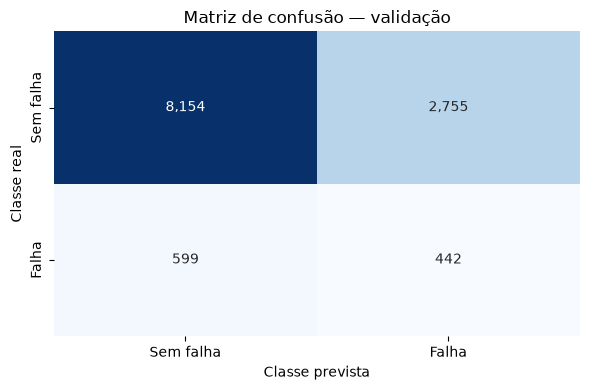

In [41]:
def calcular_metricas_classificacao(y_real, y_previsto, y_probabilidade):
    return {
        "acuracia": accuracy_score(y_real, y_previsto),
        "acuracia_balanceada": balanced_accuracy_score(
            y_real,
            y_previsto
        ),
        "precisao": precision_score(
            y_real,
            y_previsto,
            zero_division=0
        ),
        "recall": recall_score(
            y_real,
            y_previsto,
            zero_division=0
        ),
        "f1": f1_score(
            y_real,
            y_previsto,
            zero_division=0
        ),
        "pr_auc": average_precision_score(
            y_real,
            y_probabilidade
        ),
        "roc_auc": roc_auc_score(
            y_real,
            y_probabilidade
        ),
        "taxa_alertas": y_previsto.mean()
    }

previsoes_treino = pipeline_arvore_base.predict(X_treino)
probabilidades_treino = (
    pipeline_arvore_base.predict_proba(X_treino)[:, 1]
)

previsoes_validacao = pipeline_arvore_base.predict(X_validacao)
probabilidades_validacao = (
    pipeline_arvore_base.predict_proba(X_validacao)[:, 1]
)

metricas_arvore_base = pd.DataFrame({
    "Treino": calcular_metricas_classificacao(
        y_treino,
        previsoes_treino,
        probabilidades_treino
    ),
    "Validação": calcular_metricas_classificacao(
        y_validacao,
        previsoes_validacao,
        probabilidades_validacao
    )
})

matriz_confusao_validacao = confusion_matrix(
    y_validacao,
    previsoes_validacao,
    labels=[0, 1]
)

acuracia_sem_alertas = 1 - y_validacao.mean()

display(metricas_arvore_base.round(4))
print(
    "Acurácia de prever sempre 'sem falha':",
    f"{acuracia_sem_alertas:.2%}"
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    matriz_confusao_validacao,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Sem falha", "Falha"],
    yticklabels=["Sem falha", "Falha"],
    ax=ax
)
ax.set_title("Matriz de confusão — validação")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

## 13. Ajuste de hiperparâmetros

Primeiro, uma árvore auxiliar ajustada somente no treino ordena as features por importância e mantém as 13 mais úteis. Em seguida, são comparadas 60 combinações de profundidade máxima, quantidade mínima de exemplos por folha e peso da classe de falha. Nenhuma informação do teste participa dessas escolhas.

Para cada candidata, o limiar é ajustado na validação e a configuração vencedora é escolhida pelo **F1**, equilibrando precisão e recall. A PR-AUC, a acurácia balanceada e a taxa de alertas também são mantidas para interpretar os resultados. O conjunto de teste permanece intocado.

Features selecionadas: 13


,importancia
dias_desde_ultima_corretiva_30d,0.484213
horas_desde_ultimo_alarme,0.183412
qtd_dias_com_alarme_7d,0.120553
qtd_corretivas_30d,0.050370
qtd_fc_7d,0.049306
qtd_pdm_7d,0.032503
qtd_fc_30d,0.016336
qtd_dias_com_alarme_30d,0.014468
qtd_pdm_30d,0.013114
qtd_lsd_30d,0.012835


Combinações avaliadas: 60


,max_depth,min_samples_leaf,min_samples_split,peso_classe,limiar_f1,profundidade_efetiva,quantidade_folhas,pr_auc_treino,pr_auc_validacao,acuracia_balanceada,precisao,recall,f1,taxa_alertas,gap_pr_auc
0,8,500,1000,peso_3,0.2088,8,32,0.1393,0.1360,0.5924,0.1450,0.4227,0.2160,0.2539,0.0033
1,8,500,1000,balanceado,0.5108,8,32,0.1393,0.1360,0.5924,0.1450,0.4227,0.2160,0.2539,0.0033
2,10,750,1500,peso_3,0.2379,9,25,0.1322,0.1291,0.5877,0.1473,0.3919,0.2141,0.2318,0.0031
3,12,750,1500,peso_3,0.2379,9,25,0.1322,0.1291,0.5877,0.1473,0.3919,0.2141,0.2318,0.0031
4,8,750,1500,peso_3,0.2379,8,24,0.1318,0.1286,0.5877,0.1473,0.3919,0.2141,0.2318,0.0032
5,6,500,1000,peso_3,0.2321,6,20,0.1348,0.1324,0.5847,0.1483,0.3746,0.2125,0.2200,0.0024
6,6,500,1000,balanceado,0.5445,6,20,0.1348,0.1324,0.5847,0.1483,0.3746,0.2125,0.2200,0.0024
7,10,500,1000,peso_3,0.2416,10,37,0.1404,0.1367,0.5825,0.1497,0.3602,0.2115,0.2096,0.0037
8,10,500,1000,balanceado,0.5575,10,37,0.1404,0.1367,0.5825,0.1497,0.3602,0.2115,0.2096,0.0037
9,12,500,1000,peso_3,0.2416,10,37,0.1404,0.1367,0.5825,0.1497,0.3602,0.2115,0.2096,0.0037


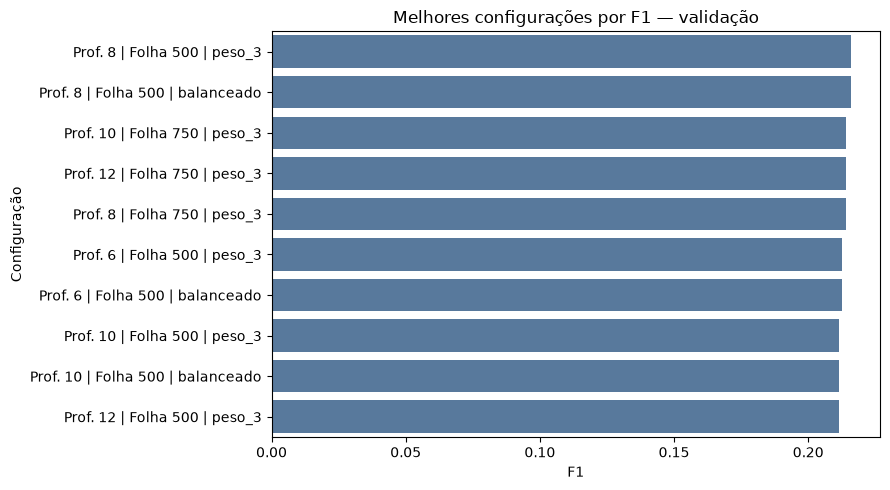

In [42]:
from itertools import product
from sklearn.metrics import precision_recall_curve

# Seleção de features usando somente o conjunto de treino
arvore_selecao_features = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=2000,
    min_samples_leaf=1000,
    random_state=42
)
arvore_selecao_features.fit(X_treino, y_treino)

ranking_features_treino = pd.Series(
    arvore_selecao_features.feature_importances_,
    index=colunas_features_modelo
).sort_values(ascending=False)

QUANTIDADE_FEATURES_SELECIONADAS = 13
colunas_features_selecionadas = (
    ranking_features_treino
    .head(QUANTIDADE_FEATURES_SELECIONADAS)
    .index
    .tolist()
)

preprocessador_arvore_selecionada = ColumnTransformer(
    transformers=[
        (
            "numericas",
            "passthrough",
            colunas_features_selecionadas
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

PROFUNDIDADES_TESTADAS = [6, 8, 10, 12]
FOLHAS_MINIMAS_TESTADAS = [100, 200, 500, 750, 1000]
PESOS_CLASSE_TESTADOS = {
    "nenhum": None,
    "peso_3": {0: 1, 1: 3},
    "balanceado": "balanced"
}

grade_hiperparametros = list(product(
    PROFUNDIDADES_TESTADAS,
    FOLHAS_MINIMAS_TESTADAS,
    PESOS_CLASSE_TESTADOS.keys()
))

X_treino_transformado = (
    preprocessador_arvore_selecionada
    .fit_transform(X_treino)
)
X_validacao_transformado = (
    preprocessador_arvore_selecionada
    .transform(X_validacao)
)

resultados_ajuste = []

for profundidade, folha_minima, nome_peso in grade_hiperparametros:
    separacao_minima = 2 * folha_minima
    peso_classe = PESOS_CLASSE_TESTADOS[nome_peso]

    arvore_candidata = DecisionTreeClassifier(
        criterion="gini",
        max_depth=profundidade,
        min_samples_split=separacao_minima,
        min_samples_leaf=folha_minima,
        class_weight=peso_classe,
        random_state=42
    )

    arvore_candidata.fit(
        X_treino_transformado,
        y_treino
    )

    probabilidade_candidata = arvore_candidata.predict_proba(
        X_validacao_transformado
    )[:, 1]
    probabilidade_candidata_treino = (
        arvore_candidata.predict_proba(
            X_treino_transformado
        )[:, 1]
    )

    precisoes_candidata, recalls_candidata, limiares_candidata = (
        precision_recall_curve(
            y_validacao,
            probabilidade_candidata
        )
    )
    denominador_f1_candidata = (
        precisoes_candidata[:-1] + recalls_candidata[:-1]
    )
    f1_candidata = np.divide(
        2
        * precisoes_candidata[:-1]
        * recalls_candidata[:-1],
        denominador_f1_candidata,
        out=np.zeros_like(denominador_f1_candidata),
        where=denominador_f1_candidata > 0
    )
    indice_limiar_candidata = int(np.argmax(f1_candidata))
    limiar_candidata = float(
        limiares_candidata[indice_limiar_candidata]
    )
    previsao_candidata = (
        probabilidade_candidata >= limiar_candidata
    ).astype("int8")

    metricas_candidata = calcular_metricas_classificacao(
        y_validacao,
        previsao_candidata,
        probabilidade_candidata
    )

    pr_auc_treino_candidata = average_precision_score(
        y_treino,
        probabilidade_candidata_treino
    )

    resultados_ajuste.append({
        "max_depth": profundidade,
        "min_samples_leaf": folha_minima,
        "min_samples_split": separacao_minima,
        "peso_classe": nome_peso,
        "limiar_f1": limiar_candidata,
        "profundidade_efetiva": arvore_candidata.get_depth(),
        "quantidade_folhas": arvore_candidata.get_n_leaves(),
        "pr_auc_treino": pr_auc_treino_candidata,
        "pr_auc_validacao": metricas_candidata["pr_auc"],
        "acuracia_balanceada": (
            metricas_candidata["acuracia_balanceada"]
        ),
        "precisao": metricas_candidata["precisao"],
        "recall": metricas_candidata["recall"],
        "f1": metricas_candidata["f1"],
        "taxa_alertas": metricas_candidata["taxa_alertas"]
    })

resultados_ajuste = pd.DataFrame(resultados_ajuste)
resultados_ajuste["gap_pr_auc"] = (
    resultados_ajuste["pr_auc_treino"]
    - resultados_ajuste["pr_auc_validacao"]
)
resultados_ajuste = (
    resultados_ajuste
    .sort_values(
        ["f1", "pr_auc_validacao"],
        ascending=False
    )
    .reset_index(drop=True)
)

melhor_configuracao = resultados_ajuste.iloc[0].copy()

print(
    "Features selecionadas:",
    len(colunas_features_selecionadas)
)
display(ranking_features_treino.head(13).to_frame("importancia"))
print(f"Combinações avaliadas: {len(resultados_ajuste)}")
display(resultados_ajuste.head(10).round(4))

top_configuracoes = resultados_ajuste.head(10).copy()
top_configuracoes["configuracao"] = (
    "Prof. "
    + top_configuracoes["max_depth"].astype(str)
    + " | Folha "
    + top_configuracoes["min_samples_leaf"].astype(str)
    + " | "
    + top_configuracoes["peso_classe"]
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=top_configuracoes,
    y="configuracao",
    x="f1",
    color="#4C78A8",
    ax=ax
)
ax.set_title("Melhores configurações por F1 — validação")
ax.set_xlabel("F1")
ax.set_ylabel("Configuração")
plt.tight_layout()
plt.show()

## 14. Seleção da Árvore de Decisão ajustada

A melhor configuração é reconstruída dentro de um pipeline com as 13 features selecionadas e novamente ajustada apenas no treino. Em seguida, ela é comparada ao baseline na validação.

Essa escolha otimiza o equilíbrio entre precisão e recall, medido pelo F1 na validação. O limiar que transforma o score em alerta será recalculado e apresentado na próxima etapa.

In [43]:
from sklearn.base import clone

parametros_selecionados = {
    "max_depth": int(melhor_configuracao["max_depth"]),
    "min_samples_leaf": int(
        melhor_configuracao["min_samples_leaf"]
    ),
    "min_samples_split": int(
        melhor_configuracao["min_samples_split"]
    )
}
nome_peso_selecionado = str(
    melhor_configuracao["peso_classe"]
)
peso_classe_selecionado = PESOS_CLASSE_TESTADOS[
    nome_peso_selecionado
]

arvore_decisao_ajustada = DecisionTreeClassifier(
    criterion="gini",
    class_weight=peso_classe_selecionado,
    random_state=42,
    **parametros_selecionados
)

pipeline_arvore_ajustada = Pipeline(steps=[
    (
        "preprocessamento",
        clone(preprocessador_arvore_selecionada)
    ),
    ("modelo", arvore_decisao_ajustada)
])
pipeline_arvore_ajustada.fit(X_treino, y_treino)

probabilidades_validacao_ajustada = (
    pipeline_arvore_ajustada.predict_proba(X_validacao)[:, 1]
)

print("Hiperparâmetros selecionados:")
print(parametros_selecionados)
print("Peso de classe selecionado:", nome_peso_selecionado)
print(
    "Profundidade efetiva:",
    pipeline_arvore_ajustada.named_steps["modelo"].get_depth()
)
print(
    "Quantidade de folhas:",
    pipeline_arvore_ajustada.named_steps["modelo"].get_n_leaves()
)

Hiperparâmetros selecionados:
{'max_depth': 8, 'min_samples_leaf': 500, 'min_samples_split': 1000}
Peso de classe selecionado: peso_3
Profundidade efetiva: 8
Quantidade de folhas: 32


## 15. Ajuste do limiar de decisão

Como ainda não foi definido um custo operacional para falsos positivos e falsos negativos, o limiar é escolhido pela maximização do **F1 na validação**, um critério técnico que equilibra precisão e recall.

A busca selecionou peso 3 para a classe de falha, dando mais atenção às falhas, que são menos frequentes. A saída da árvore deve ser interpretada como um **score de risco**, pois não foi calibrada como probabilidade. O limiar poderá ser alterado futuramente conforme a capacidade de inspeção e o custo de não detectar uma falha. O teste continua intocado.

Limiar selecionado: 0.2088
Taxa de alertas na validação: 25.39%


,Baseline,Árvore aprimorada
acuracia,0.7193,0.7326
acuracia_balanceada,0.5860,0.5924
precisao,0.1383,0.1450
recall,0.4246,0.4227
f1,0.2086,0.2160
pr_auc,0.1351,0.1360
roc_auc,0.5945,0.6107
taxa_alertas,0.2675,0.2539


,limiar,precisao,recall,f1,acuracia_balanceada,taxa_alertas
0,0.1000,0.0897,0.9443,0.1638,0.5147,0.9174
1,0.1500,0.0915,0.9116,0.1664,0.5241,0.8676
2,0.2088,0.1450,0.4227,0.2160,0.5924,0.2539
3,0.2500,0.1544,0.3247,0.2093,0.5775,0.1832
4,0.3000,0.1586,0.2430,0.1920,0.5600,0.1335
5,0.3500,0.1974,0.1758,0.1860,0.5538,0.0776


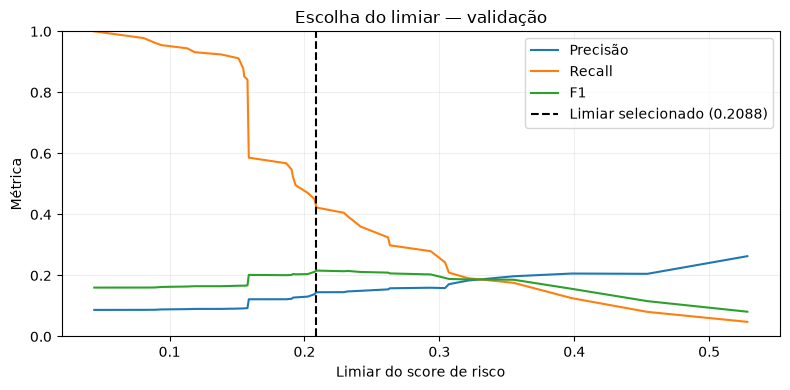

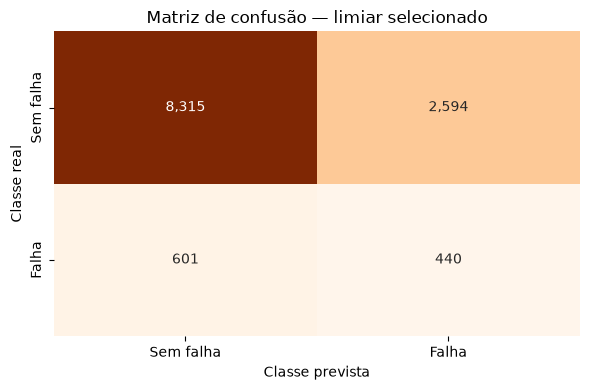

In [44]:
from sklearn.metrics import precision_recall_curve

precisoes_curva, recalls_curva, limiares_curva = (
    precision_recall_curve(
        y_validacao,
        probabilidades_validacao_ajustada
    )
)

# O último ponto de precisão/recall não possui limiar correspondente
precisoes_por_limiar = precisoes_curva[:-1]
recalls_por_limiar = recalls_curva[:-1]
denominador_f1 = precisoes_por_limiar + recalls_por_limiar
f1_por_limiar = np.divide(
    2 * precisoes_por_limiar * recalls_por_limiar,
    denominador_f1,
    out=np.zeros_like(denominador_f1),
    where=denominador_f1 > 0
)

indice_melhor_limiar = int(np.argmax(f1_por_limiar))
LIMIAR_SELECIONADO = float(
    limiares_curva[indice_melhor_limiar]
)

def avaliar_limiar(limiar):
    previsoes = (
        probabilidades_validacao_ajustada >= limiar
    ).astype("int8")

    return {
        "limiar": limiar,
        "precisao": precision_score(
            y_validacao,
            previsoes,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao,
            previsoes,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao,
            previsoes,
            zero_division=0
        ),
        "acuracia_balanceada": balanced_accuracy_score(
            y_validacao,
            previsoes
        ),
        "taxa_alertas": previsoes.mean()
    }

limiares_comparacao = sorted(set([
    0.10,
    0.15,
    LIMIAR_SELECIONADO,
    0.25,
    0.30,
    0.35
]))

comparacao_limiares = pd.DataFrame([
    avaliar_limiar(limiar)
    for limiar in limiares_comparacao
])

previsoes_validacao_limiar = (
    probabilidades_validacao_ajustada
    >= LIMIAR_SELECIONADO
).astype("int8")

metricas_validacao_limiar = calcular_metricas_classificacao(
    y_validacao,
    previsoes_validacao_limiar,
    probabilidades_validacao_ajustada
)

previsoes_validacao_ajustada = previsoes_validacao_limiar.copy()
metricas_ajustada_validacao = metricas_validacao_limiar.copy()
comparacao_modelos_validacao = pd.DataFrame({
    "Baseline": metricas_arvore_base["Validação"],
    "Árvore aprimorada": pd.Series(
        metricas_ajustada_validacao
    )
})

matriz_confusao_validacao_limiar = confusion_matrix(
    y_validacao,
    previsoes_validacao_limiar,
    labels=[0, 1]
)

print(f"Limiar selecionado: {LIMIAR_SELECIONADO:.4f}")
print(
    "Taxa de alertas na validação:",
    f"{previsoes_validacao_limiar.mean():.2%}"
)
display(comparacao_modelos_validacao.round(4))
display(comparacao_limiares.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    limiares_curva,
    precisoes_por_limiar,
    label="Precisão"
)
ax.plot(
    limiares_curva,
    recalls_por_limiar,
    label="Recall"
)
ax.plot(
    limiares_curva,
    f1_por_limiar,
    label="F1"
)
ax.axvline(
    LIMIAR_SELECIONADO,
    color="black",
    linestyle="--",
    label=f"Limiar selecionado ({LIMIAR_SELECIONADO:.4f})"
)
ax.set_title("Escolha do limiar — validação")
ax.set_xlabel("Limiar do score de risco")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    matriz_confusao_validacao_limiar,
    annot=True,
    fmt=",d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Sem falha", "Falha"],
    yticklabels=["Sem falha", "Falha"],
    ax=ax
)
ax.set_title("Matriz de confusão — limiar selecionado")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

## 16. Avaliação final no conjunto de teste

Com hiperparâmetros e limiar congelados, o conjunto de teste é utilizado uma única vez para estimar a generalização temporal do modelo. Nenhuma decisão de modelagem é alterada com base nesse resultado.

A avaliação mantém as mesmas métricas usadas na validação e aplica o limiar selecionado ao score de cada PSD uma vez por semana.

Limiar aplicado ao teste: 0.2088
Média de PSDs alertadas por semana: 77.9


,Validação,Teste
acuracia,0.7326,0.7689
acuracia_balanceada,0.5924,0.5621
precisao,0.1450,0.1242
recall,0.4227,0.3163
f1,0.2160,0.1784
pr_auc,0.1360,0.1065
roc_auc,0.6107,0.5713
taxa_alertas,0.2539,0.2019



Relatório de classificação — teste final
Classe 0 = sem falha | Classe 1 = falha

              precision    recall  f1-score   support

           0       0.93      0.81      0.87      8881
           1       0.12      0.32      0.18       765

    accuracy                           0.77      9646
   macro avg       0.53      0.56      0.52      9646
weighted avg       0.87      0.77      0.81      9646



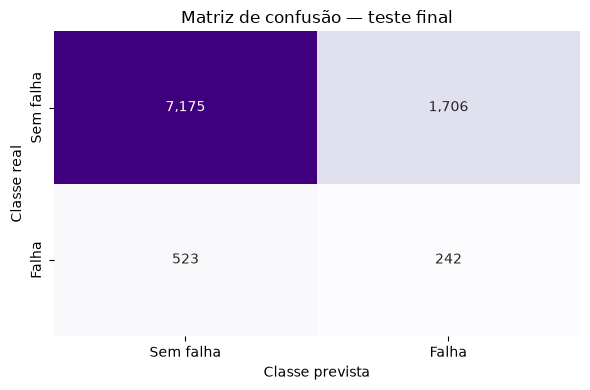

In [45]:
probabilidades_teste_final = (
    pipeline_arvore_ajustada.predict_proba(X_teste)[:, 1]
)
previsoes_teste_final = (
    probabilidades_teste_final >= LIMIAR_SELECIONADO
).astype("int8")

metricas_teste_final = calcular_metricas_classificacao(
    y_teste,
    previsoes_teste_final,
    probabilidades_teste_final
)

comparacao_validacao_teste = pd.DataFrame({
    "Validação": pd.Series(metricas_validacao_limiar),
    "Teste": pd.Series(metricas_teste_final)
})

matriz_confusao_teste = confusion_matrix(
    y_teste,
    previsoes_teste_final,
    labels=[0, 1]
)

dados_teste_resultados = dados_teste[
    [
        "id_psd",
        "data_referencia",
        "estacao",
        "target_falha_7d"
    ]
].copy()
dados_teste_resultados["score_risco"] = (
    probabilidades_teste_final
)
dados_teste_resultados["alerta_previsto"] = (
    previsoes_teste_final
)

assert len(dados_teste_resultados) == len(dados_teste)
assert dados_teste_resultados.isna().sum().sum() == 0

alertas_por_semana_teste = (
    dados_teste_resultados["alerta_previsto"].sum()
    / dados_teste_resultados["data_referencia"].nunique()
)

print(f"Limiar aplicado ao teste: {LIMIAR_SELECIONADO:.4f}")
print(
    "Média de PSDs alertadas por semana:",
    f"{alertas_por_semana_teste:.1f}"
)
display(comparacao_validacao_teste.round(4))

print("\nRelatório de classificação — teste final")
print("Classe 0 = sem falha | Classe 1 = falha\n")
print(
    classification_report(
        y_teste,
        previsoes_teste_final,
        labels=[0, 1],
        digits=2,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    matriz_confusao_teste,
    annot=True,
    fmt=",d",
    cmap="Purples",
    cbar=False,
    xticklabels=["Sem falha", "Falha"],
    yticklabels=["Sem falha", "Falha"],
    ax=ax
)
ax.set_title("Matriz de confusão — teste final")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

## 17. Estabilidade temporal e mudança de cobertura

A quantidade de PSDs com dados disponíveis diminui em janeiro de 2026. Para não esconder o efeito dessa mudança, o teste é apresentado de forma geral e também separado antes e depois de 01/01/2026.

Essa análise é apenas diagnóstica: ela não é usada para escolher novos parâmetros ou outro limiar.

,periodo,data_inicial,data_final,linhas,psds,taxa_falha_real,pr_auc,acuracia_balanceada,precisao,recall,f1,taxa_alertas
0,Teste completo,2025-10-05,2026-03-22,9646,478,0.0793,0.1065,0.5621,0.1242,0.3163,0.1784,0.2019
1,Out-Dez/2025,2025-10-05,2025-12-28,6214,478,0.0808,0.1084,0.5558,0.1188,0.3207,0.1734,0.2181
2,Jan-Mar/2026,2026-01-04,2026-03-22,3432,286,0.0766,0.1020,0.5732,0.1366,0.3080,0.1893,0.1728


Estações que deixam de aparecer em 2026: ['MBI', 'PIN', 'REP', 'VSO']


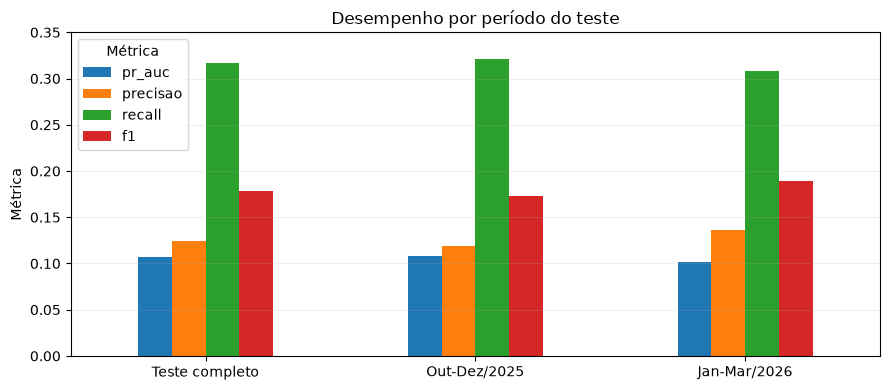

In [46]:
DATA_MUDANCA_COBERTURA = pd.Timestamp("2026-01-01")

mascara_teste_2025 = (
    dados_teste_resultados["data_referencia"]
    < DATA_MUDANCA_COBERTURA
)
mascara_teste_2026 = ~mascara_teste_2025

def resumir_periodo_teste(nome, dados):
    metricas = calcular_metricas_classificacao(
        dados["target_falha_7d"],
        dados["alerta_previsto"],
        dados["score_risco"]
    )

    return {
        "periodo": nome,
        "data_inicial": dados["data_referencia"].min().date(),
        "data_final": dados["data_referencia"].max().date(),
        "linhas": len(dados),
        "psds": dados["id_psd"].nunique(),
        "taxa_falha_real": dados["target_falha_7d"].mean(),
        "pr_auc": metricas["pr_auc"],
        "acuracia_balanceada": metricas["acuracia_balanceada"],
        "precisao": metricas["precisao"],
        "recall": metricas["recall"],
        "f1": metricas["f1"],
        "taxa_alertas": metricas["taxa_alertas"]
    }

resumo_periodos_teste = pd.DataFrame([
    resumir_periodo_teste(
        "Teste completo",
        dados_teste_resultados
    ),
    resumir_periodo_teste(
        "Out-Dez/2025",
        dados_teste_resultados.loc[mascara_teste_2025]
    ),
    resumir_periodo_teste(
        "Jan-Mar/2026",
        dados_teste_resultados.loc[mascara_teste_2026]
    )
])

assert (
    mascara_teste_2025.sum() + mascara_teste_2026.sum()
    == len(dados_teste_resultados)
)

estacoes_2025 = set(
    dados_teste_resultados.loc[
        mascara_teste_2025,
        "estacao"
    ].unique()
)
estacoes_2026 = set(
    dados_teste_resultados.loc[
        mascara_teste_2026,
        "estacao"
    ].unique()
)
estacoes_sem_cobertura_2026 = sorted(
    estacoes_2025 - estacoes_2026
)

display(resumo_periodos_teste.round(4))
print(
    "Estações que deixam de aparecer em 2026:",
    estacoes_sem_cobertura_2026
)

metricas_grafico = [
    "pr_auc",
    "precisao",
    "recall",
    "f1"
]
ax = (
    resumo_periodos_teste
    .set_index("periodo")[metricas_grafico]
    .plot(kind="bar", figsize=(9, 4))
)
ax.set_title("Desempenho por período do teste")
ax.set_xlabel("")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 0.35)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Métrica")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 18. Avaliação por evento corretivo

As métricas anteriores avaliam uma previsão semanal por PSD. Cada evento corretivo é considerado detectado quando a previsão semanal da mesma PSD gerou um alerta entre 1 e 7 dias antes da ocorrência.

Entra nessa análise somente o evento que possui uma data semanal de referência disponível no teste.

Período dos eventos avaliados: 2025-10-06 até 2026-03-29


,periodo,eventos_avaliados,eventos_detectados,taxa_deteccao_eventos,antecedencia_media_dias,antecedencia_mediana_dias
0,Teste completo,888,293,0.3300,3.5597,3.0
1,Out-Dez/2025,567,194,0.3422,3.5258,3.0
2,Jan-Mar/2026,321,99,0.3084,3.6263,4.0


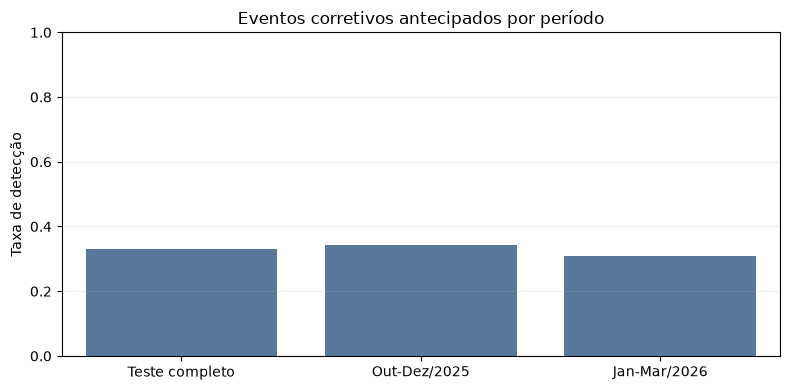

In [47]:
referencias_eventos_teste = pd.concat(
    [
        eventos_corretivos_diarios.assign(
            data_referencia=(
                eventos_corretivos_diarios["data_evento"]
                - pd.Timedelta(days=deslocamento)
            ),
            dias_antecedencia=deslocamento
        )
        for deslocamento in range(
            1,
            HORIZONTE_PREVISAO_DIAS + 1
        )
    ],
    ignore_index=True
)

alertas_antes_eventos = referencias_eventos_teste.merge(
    dados_teste_resultados[
        ["id_psd", "data_referencia", "alerta_previsto"]
    ],
    on=["id_psd", "data_referencia"],
    how="inner",
    validate="many_to_one"
)

alertas_antes_eventos["antecedencia_alerta"] = (
    alertas_antes_eventos["dias_antecedencia"].where(
        alertas_antes_eventos["alerta_previsto"] == 1
    )
)

eventos_teste_avaliaveis = (
    alertas_antes_eventos
    .groupby(
        ["id_psd", "data_evento"],
        as_index=False
    )
    .agg(
        dias_avaliaveis=("data_referencia", "nunique"),
        detectado=("alerta_previsto", "max"),
        antecedencia_maxima_dias=(
            "antecedencia_alerta",
            "max"
        )
    )
)
eventos_teste_avaliaveis = eventos_teste_avaliaveis[
    eventos_teste_avaliaveis["dias_avaliaveis"] == 1
].copy()

def resumir_eventos(nome, eventos):
    eventos_detectados = eventos[
        eventos["detectado"] == 1
    ]

    return {
        "periodo": nome,
        "eventos_avaliados": len(eventos),
        "eventos_detectados": int(eventos["detectado"].sum()),
        "taxa_deteccao_eventos": eventos["detectado"].mean(),
        "antecedencia_media_dias": (
            eventos_detectados["antecedencia_maxima_dias"].mean()
        ),
        "antecedencia_mediana_dias": (
            eventos_detectados["antecedencia_maxima_dias"].median()
        )
    }

eventos_2025 = eventos_teste_avaliaveis[
    eventos_teste_avaliaveis["data_evento"]
    < DATA_MUDANCA_COBERTURA
]
eventos_2026 = eventos_teste_avaliaveis[
    eventos_teste_avaliaveis["data_evento"]
    >= DATA_MUDANCA_COBERTURA
]

resumo_eventos_teste = pd.DataFrame([
    resumir_eventos(
        "Teste completo",
        eventos_teste_avaliaveis
    ),
    resumir_eventos("Out-Dez/2025", eventos_2025),
    resumir_eventos("Jan-Mar/2026", eventos_2026)
])

assert (
    eventos_teste_avaliaveis["dias_avaliaveis"] == 1
).all()

print(
    "Período dos eventos avaliados:",
    eventos_teste_avaliaveis["data_evento"].min().date(),
    "até",
    eventos_teste_avaliaveis["data_evento"].max().date()
)
display(resumo_eventos_teste.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=resumo_eventos_teste,
    x="periodo",
    y="taxa_deteccao_eventos",
    color="#4C78A8",
    ax=ax
)
ax.set_title("Eventos corretivos antecipados por período")
ax.set_xlabel("")
ax.set_ylabel("Taxa de detecção")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 19. Desempenho por estação

Embora a estação tenha sido removida das features do modelo, a cobertura não é constante ao longo do teste. Por isso, as métricas também são calculadas separadamente por estação usando essa coluna apenas como metadado de auditoria. A taxa real de falhas funciona como referência para a PR-AUC: um ranqueamento aleatório teria PR-AUC aproximadamente igual a essa prevalência.

Essa análise identifica diferenças de generalização, mas não é usada para reajustar o modelo após a abertura do teste.

,estacao,linhas,psds,falhas_positivas,taxa_falha_real,pr_auc,acuracia_balanceada,precisao,recall,f1,taxa_alertas
0,REP,624,48,86,0.1378,0.1857,0.5064,0.1422,0.3605,0.2039,0.3494
1,PIN,624,48,74,0.1186,0.1431,0.5515,0.1478,0.4595,0.2237,0.3686
2,FRA,1200,48,102,0.0850,0.1412,0.5643,0.1259,0.3627,0.1869,0.2450
3,HIG,1200,48,104,0.0867,0.1408,0.5965,0.1674,0.3654,0.2296,0.1892
4,VSO,624,48,39,0.0625,0.0962,0.6009,0.1104,0.4359,0.1762,0.2468
5,BUT,1200,48,88,0.0733,0.0954,0.5403,0.1093,0.2273,0.1476,0.1525
6,FAL,1200,48,83,0.0692,0.0896,0.5618,0.1325,0.2410,0.1709,0.1258
7,FRE,1150,46,90,0.0783,0.0811,0.5059,0.0859,0.1222,0.1009,0.1113
8,MBI,624,48,40,0.0641,0.0771,0.5387,0.0845,0.3000,0.1319,0.2276
9,LUZ,1200,48,59,0.0492,0.0684,0.5992,0.0995,0.3729,0.1571,0.1842


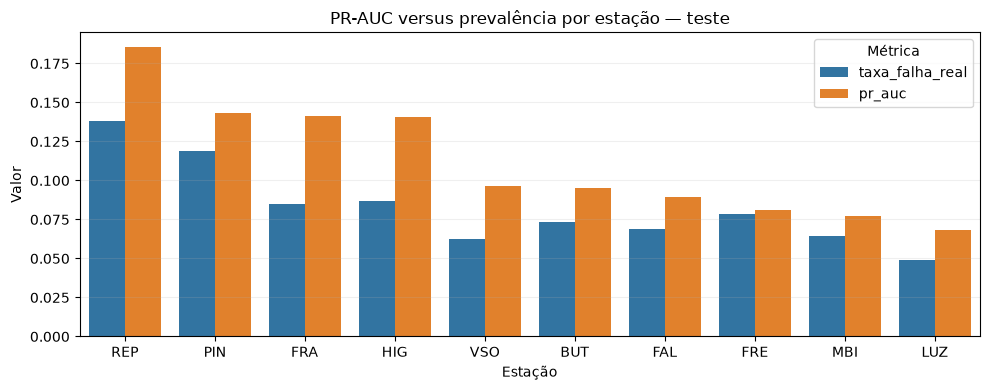

In [48]:
def resumir_estacao(estacao, dados):
    y_estacao = dados["target_falha_7d"]
    previsao_estacao = dados["alerta_previsto"]
    score_estacao = dados["score_risco"]
    possui_duas_classes = y_estacao.nunique() == 2

    return {
        "estacao": estacao,
        "linhas": len(dados),
        "psds": dados["id_psd"].nunique(),
        "falhas_positivas": int(y_estacao.sum()),
        "taxa_falha_real": y_estacao.mean(),
        "pr_auc": (
            average_precision_score(y_estacao, score_estacao)
            if possui_duas_classes
            else np.nan
        ),
        "acuracia_balanceada": (
            balanced_accuracy_score(
                y_estacao,
                previsao_estacao
            )
            if possui_duas_classes
            else np.nan
        ),
        "precisao": precision_score(
            y_estacao,
            previsao_estacao,
            zero_division=0
        ),
        "recall": recall_score(
            y_estacao,
            previsao_estacao,
            zero_division=0
        ),
        "f1": f1_score(
            y_estacao,
            previsao_estacao,
            zero_division=0
        ),
        "taxa_alertas": previsao_estacao.mean()
    }

resumo_estacoes_teste = pd.DataFrame([
    resumir_estacao(estacao, dados_estacao)
    for estacao, dados_estacao in dados_teste_resultados.groupby(
        "estacao",
        sort=True
    )
])
resumo_estacoes_teste = (
    resumo_estacoes_teste
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(resumo_estacoes_teste.round(4))

dados_estacoes_grafico = resumo_estacoes_teste.melt(
    id_vars="estacao",
    value_vars=["taxa_falha_real", "pr_auc"],
    var_name="metrica",
    value_name="valor"
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=dados_estacoes_grafico,
    x="estacao",
    y="valor",
    hue="metrica",
    ax=ax
)
ax.set_title("PR-AUC versus prevalência por estação — teste")
ax.set_xlabel("Estação")
ax.set_ylabel("Valor")
ax.legend(title="Métrica")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 20. Importância das features

A importância nativa da árvore representa quanto cada feature reduziu a impureza dos nós durante o treinamento. Ela ajuda a entender quais variáveis orientaram as divisões, mas **não demonstra causalidade nem informa a direção do efeito**.

Features correlacionadas, como as mesmas medidas nas janelas de 1, 7 e 30 dias, competem entre si. Variáveis contínuas também oferecem mais possibilidades de corte. Por isso, as importâncias são apresentadas individualmente e agrupadas por família, e devem ser interpretadas como associações do modelo.

Features com importância maior que zero: 13


,feature,importancia,importancia_acumulada,familia
0,dias_desde_ultima_corretiva_30d,0.3862,0.3862,Histórico de corretivas
1,horas_desde_ultimo_alarme,0.1821,0.5683,Recência e ausência
2,qtd_dias_com_alarme_7d,0.0950,0.6633,Dias com alarme
4,qtd_fc_7d,0.0882,0.7515,Tipos de alarme
5,qtd_pdm_7d,0.0639,0.8154,Componentes PDM/MDU
10,qtd_csd_30d,0.0617,0.8771,Tipos de alarme
3,qtd_corretivas_30d,0.0433,0.9204,Histórico de corretivas
9,qtd_lsd_30d,0.0187,0.9391,Tipos de alarme
6,qtd_fc_30d,0.0182,0.9573,Tipos de alarme
7,qtd_dias_com_alarme_30d,0.0155,0.9729,Dias com alarme


,familia,importancia
2,Histórico de corretivas,0.4295
4,Tipos de alarme,0.1934
3,Recência e ausência,0.1821
1,Dias com alarme,0.1106
0,Componentes PDM/MDU,0.0791
5,Volume total de alarmes,0.0054


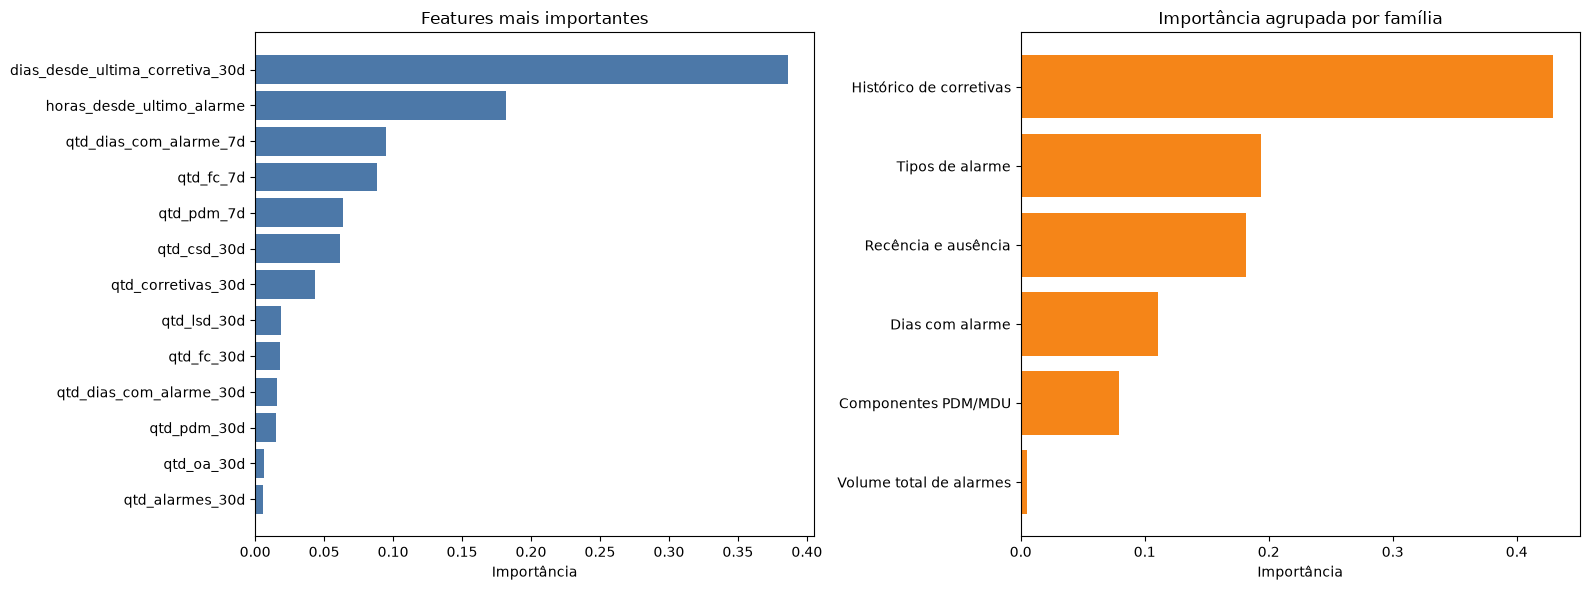

In [49]:
preprocessador_final = (
    pipeline_arvore_ajustada.named_steps["preprocessamento"]
)
arvore_final = pipeline_arvore_ajustada.named_steps["modelo"]
nomes_features_finais = preprocessador_final.get_feature_names_out()

importancias_features = pd.DataFrame({
    "feature": nomes_features_finais,
    "importancia": arvore_final.feature_importances_
}).sort_values("importancia", ascending=False)
importancias_features["importancia_acumulada"] = (
    importancias_features["importancia"].cumsum()
)

def classificar_familia_feature(feature):
    if (
        feature.startswith("estacao_")
        or feature.startswith("via_")
        or feature == "posicao_psd"
    ):
        return "Contexto da PSD"
    if (
        feature.startswith("dia_semana_")
        or feature.startswith("mes_")
        or feature == "fim_de_semana"
    ):
        return "Calendário"
    if feature.startswith("duracao_"):
        return "Duração dos alarmes"
    if (
        feature.startswith("qtd_corretivas_")
        or feature in [
            "dias_desde_ultima_corretiva_30d",
            "sem_corretiva_30d"
        ]
    ):
        return "Histórico de corretivas"
    if feature.startswith("qtd_dias_com_alarme_"):
        return "Dias com alarme"
    if feature.startswith(("qtd_pdm_", "qtd_mdu_")):
        return "Componentes PDM/MDU"
    if feature.startswith("qtd_criticos_"):
        return "Alarmes críticos"
    if feature.startswith("qtd_alarmes_"):
        return "Volume total de alarmes"
    if feature.startswith("qtd_"):
        return "Tipos de alarme"
    if feature in [
        "horas_desde_ultimo_alarme",
        "sem_alarme_30d"
    ]:
        return "Recência e ausência"
    return "Outras"

importancias_features["familia"] = (
    importancias_features["feature"]
    .map(classificar_familia_feature)
)

importancias_familias = (
    importancias_features
    .groupby("familia", as_index=False)["importancia"]
    .sum()
    .sort_values("importancia", ascending=False)
)

assert len(nomes_features_finais) == len(
    arvore_final.feature_importances_
)
assert np.isclose(importancias_features["importancia"].sum(), 1)

quantidade_features_utilizadas = int(
    (importancias_features["importancia"] > 0).sum()
)
print(
    "Features com importância maior que zero:",
    quantidade_features_utilizadas
)
display(importancias_features.head(15).round(4))
display(importancias_familias.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_features = (
    importancias_features.head(15).sort_values("importancia")
)
axes[0].barh(
    top_features["feature"],
    top_features["importancia"],
    color="#4C78A8"
)
axes[0].set_title("Features mais importantes")
axes[0].set_xlabel("Importância")

familias_ordenadas = importancias_familias.sort_values(
    "importancia"
)
axes[1].barh(
    familias_ordenadas["familia"],
    familias_ordenadas["importancia"],
    color="#F58518"
)
axes[1].set_title("Importância agrupada por família")
axes[1].set_xlabel("Importância")

plt.tight_layout()
plt.show()

## 21. Visualização das regras iniciais da árvore

A árvore final possui diversos nós e sua visualização completa seria ilegível. São exibidos apenas os três primeiros níveis, suficientes para observar as regras que iniciam a segmentação do risco.

A configuração final atribui peso 3 à classe de falha. As regras devem ser interpretadas como decisões do modelo, não como relações causais.

|--- dias_desde_ultima_corretiva_30d <= 17.50
|   |--- horas_desde_ultimo_alarme <= 30.44
|   |   |--- class: 1
|   |--- horas_desde_ultimo_alarme >  30.44
|   |   |--- qtd_corretivas_30d <= 1.50
|   |   |   |--- dias_desde_ultima_corretiva_30d <= 4.50
|   |   |   |   |--- class: 0
|   |   |   |--- dias_desde_ultima_corretiva_30d >  4.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- qtd_corretivas_30d >  1.50
|   |   |   |--- qtd_csd_30d <= 3.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- qtd_csd_30d >  3.50
|   |   |   |   |--- class: 0
|--- dias_desde_ultima_corretiva_30d >  17.50
|   |--- qtd_dias_com_alarme_7d <= 1.50
|   |   |--- qtd_fc_7d <= 5.50
|   |   |   |--- horas_desde_ultimo_alarme <= 211.22
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- horas_desde_ultimo_alarme >  211.22
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- qtd_fc_7d >  5.50
|   |   |   |--- class: 0
|   |--- qtd_dias_com_alarme_7d >  1.50


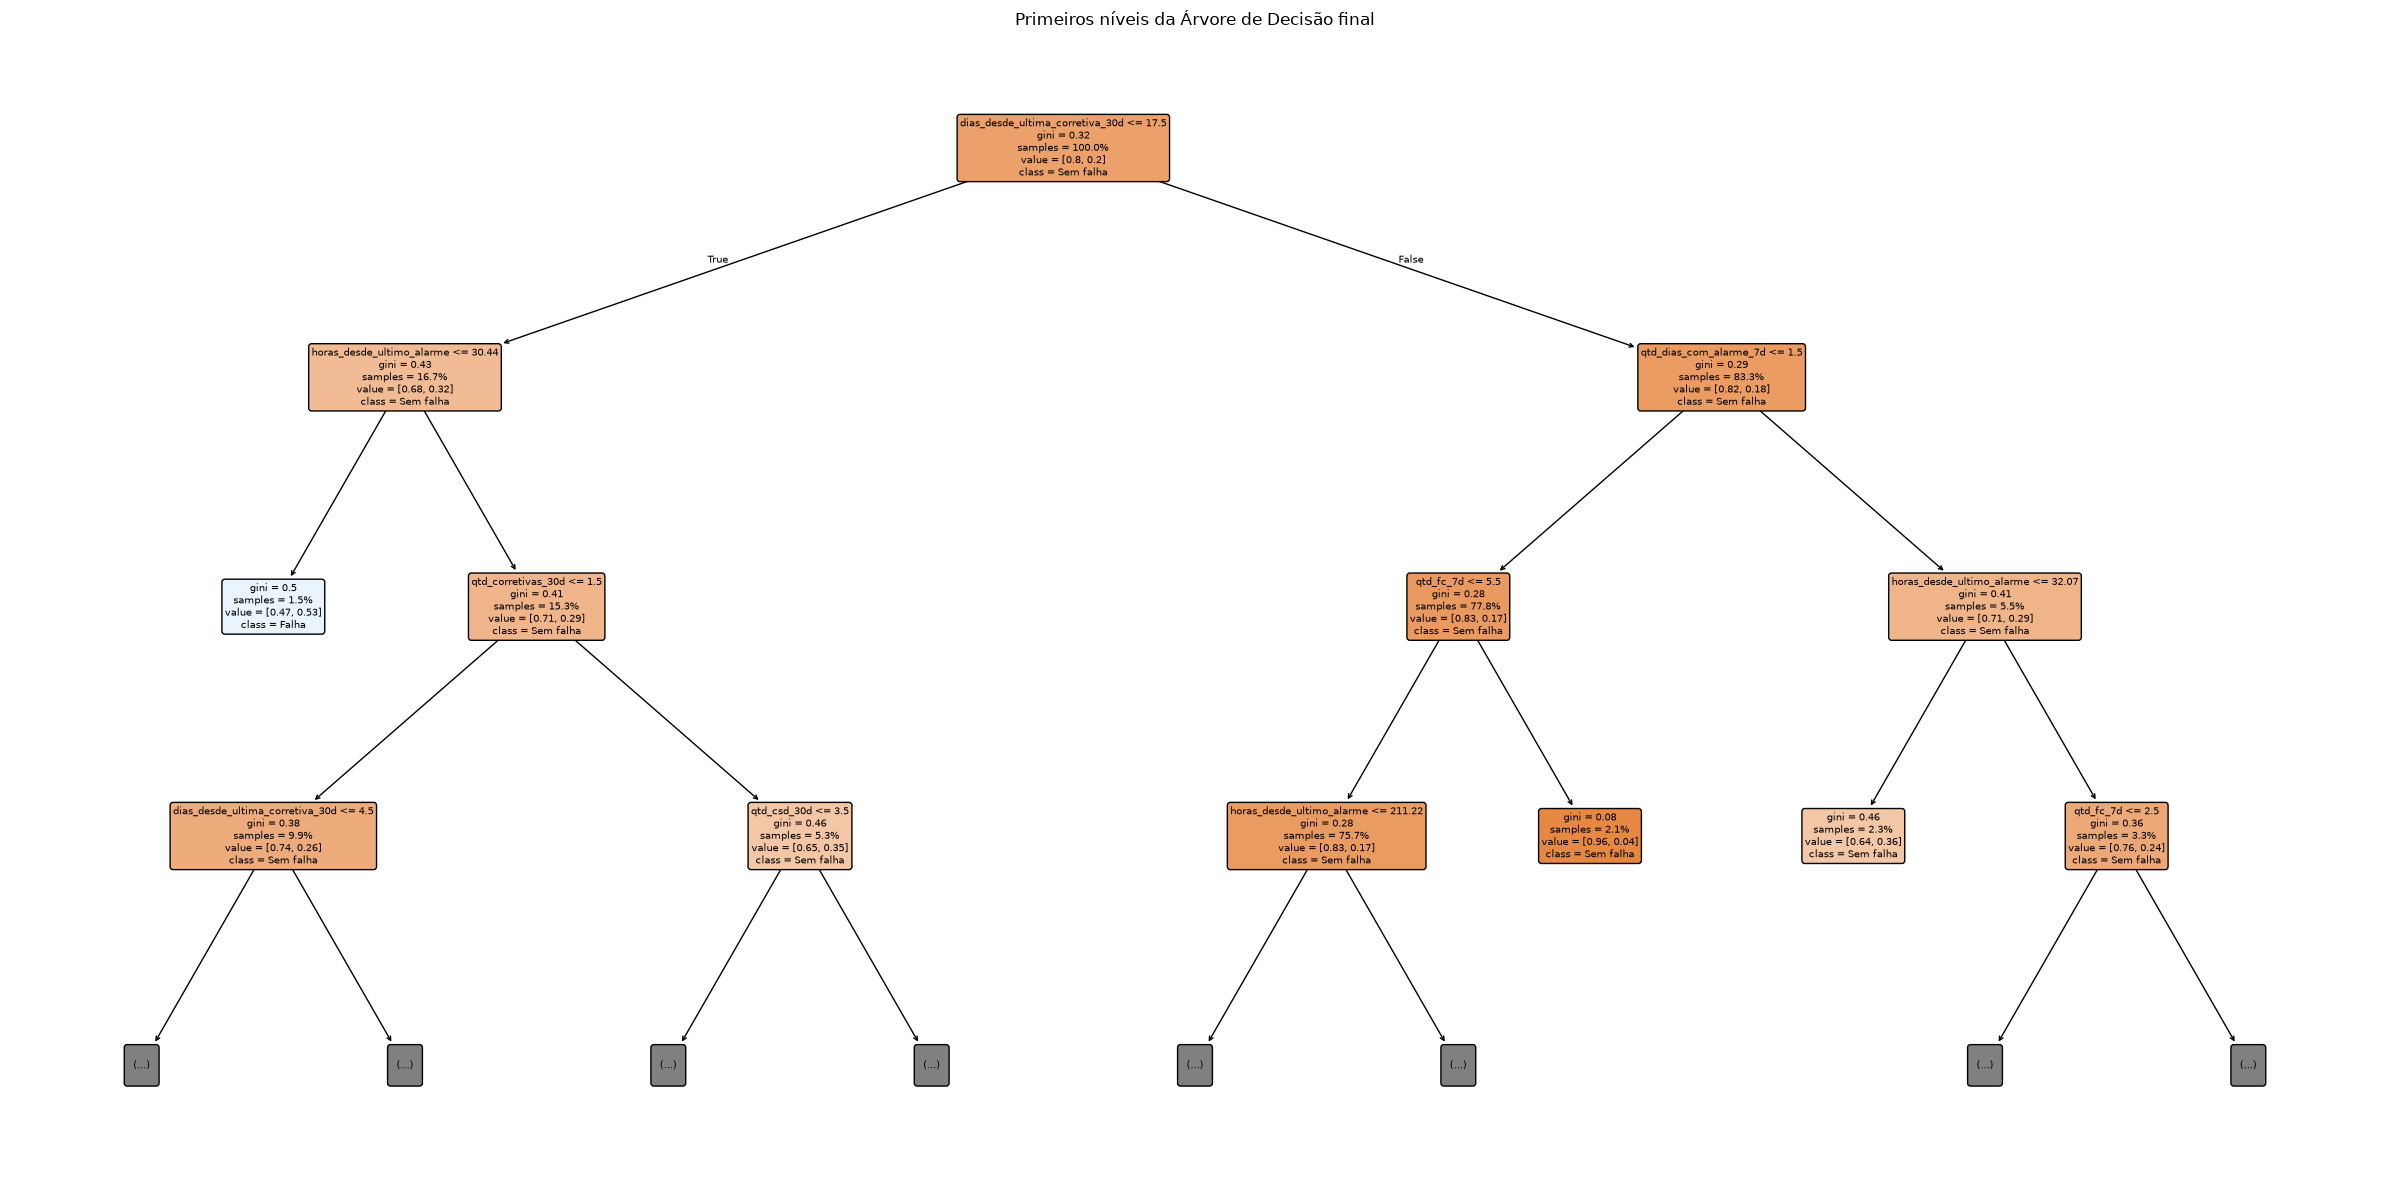

In [50]:
from sklearn.tree import export_text, plot_tree

regras_iniciais = export_text(
    arvore_final,
    feature_names=list(nomes_features_finais),
    max_depth=3,
    decimals=2
)
print(regras_iniciais)

fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(
    arvore_final,
    feature_names=list(nomes_features_finais),
    class_names=["Sem falha", "Falha"],
    max_depth=3,
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    fontsize=7,
    ax=ax
)
ax.set_title("Primeiros níveis da Árvore de Decisão final")
plt.tight_layout()
plt.show()

## 22. Conclusão e limitações

O modelo foi criado para prever se uma PSD apresentará falha nos **próximos sete dias**. As previsões são realizadas semanalmente, utilizando 13 features e desconsiderando alarmes com menos de 30 segundos.

No teste, o modelo obteve:

- **Precisão de 12,42%:** aproximadamente 12 de cada 100 alertas indicaram uma falha registrada;
- **Recall de 31,63%:** aproximadamente 32 de cada 100 falhas foram identificadas.

### Limitações

- As ordens ZM01 foram usadas como indicação de falha, mas podem não representar uma quebra física confirmada;
- Algumas ordens podem pertencer ao mesmo incidente;
- Existem mudanças e possíveis interrupções na cobertura dos dados;
- A quantidade de falsos alertas ainda é elevada.

Portanto, o modelo deve ser considerado uma **prova de conceito**. Antes de uma aplicação real, é necessário validar as falhas com especialistas e melhorar a qualidade dos dados.